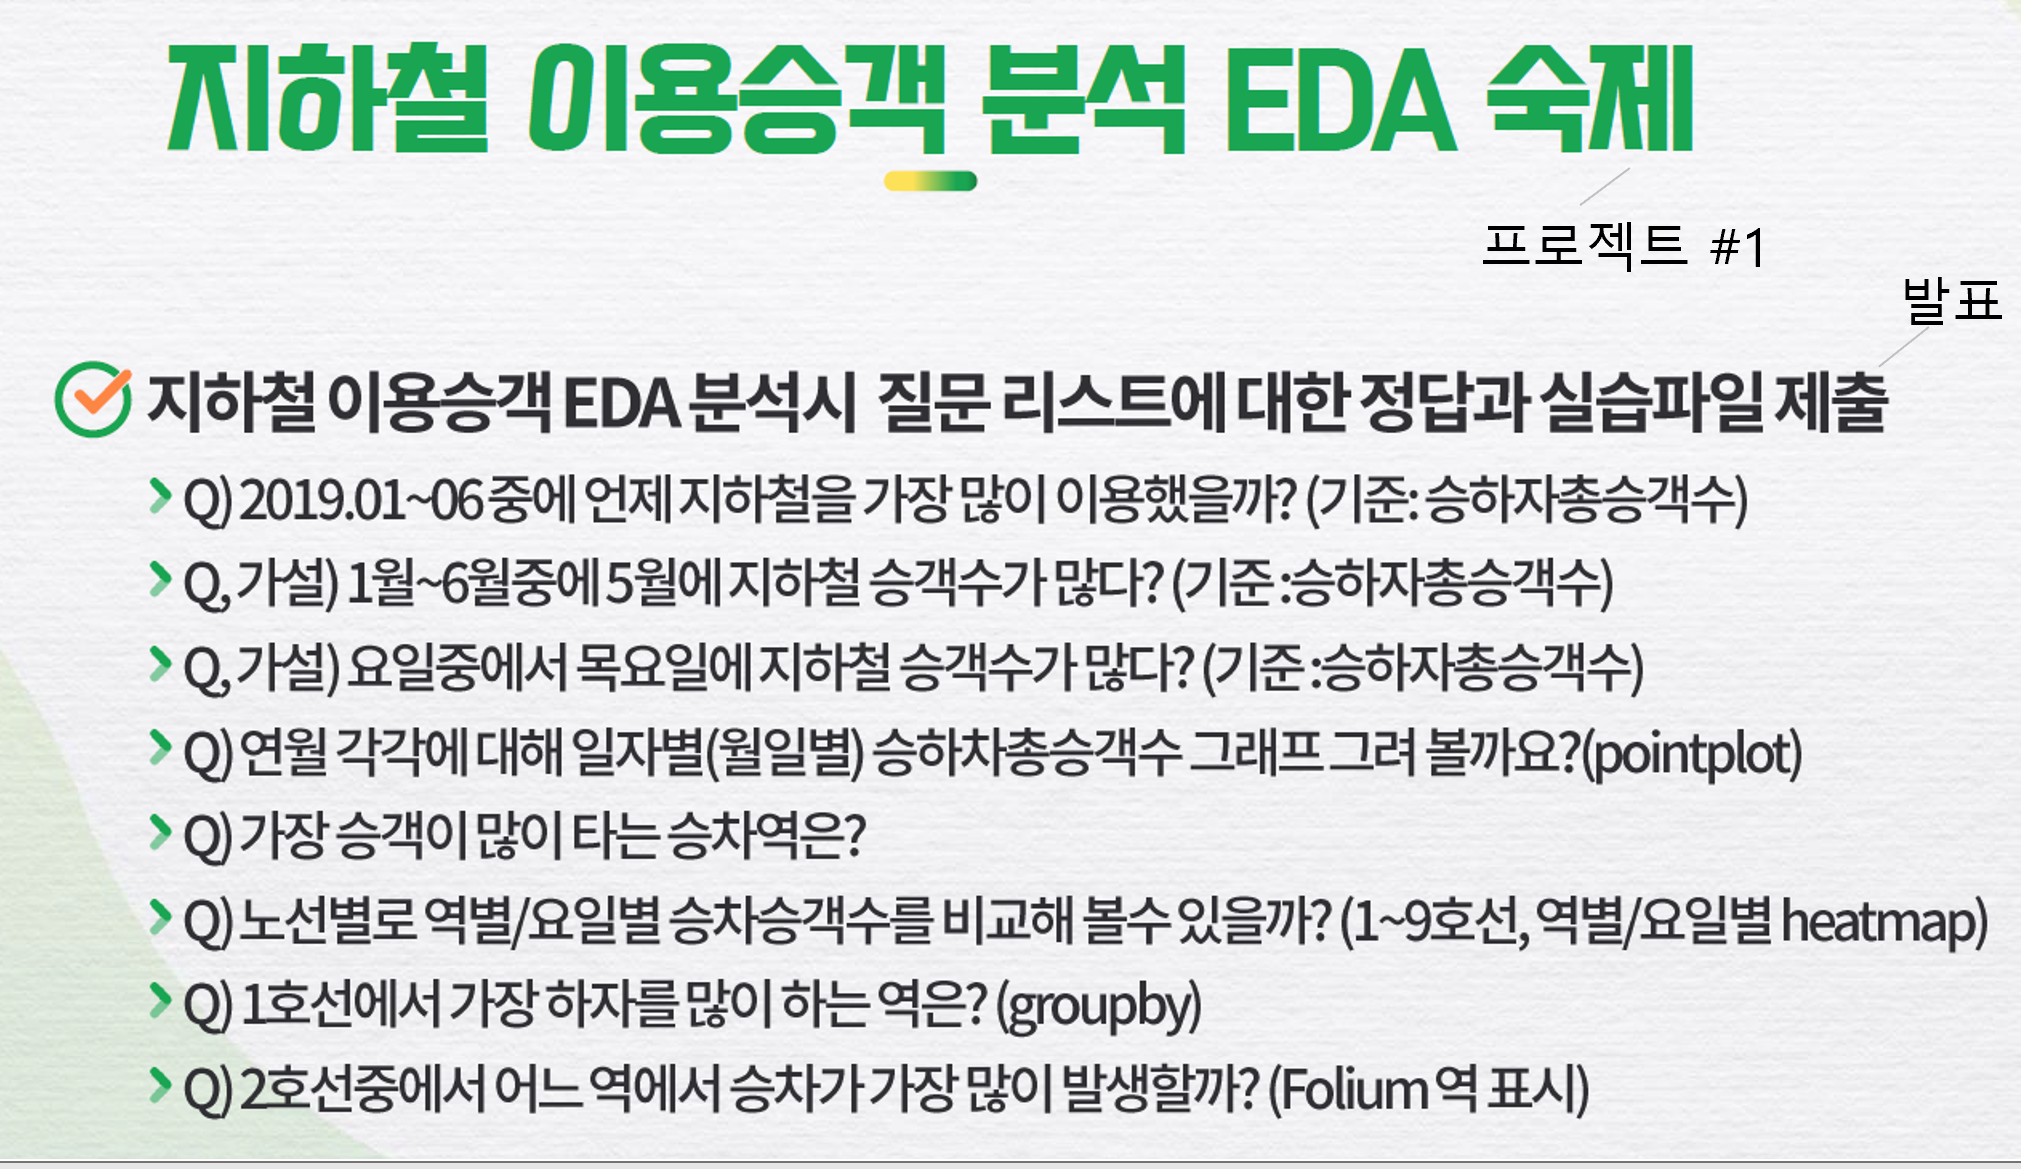

# "지하철 이용승객 분석" EDA 프로젝트(1)
- 이번 프로젝트에서는 EDA가 무엇이고 , 실습을 통해 EDA 하는 방법을 배워보겠습니다.
- EDA(Exploratory Data Analysis 탐색적 데이터 분석)는 데이터를 이해하는 과정이며
- 통계적 요약, 분포 파악 및 시각화 등의 기법을 통해 직관적으로 데이터 특성 파악 할수 있습니다.
- 결국, EDA를 통해 데이터에서 트랜드 분석, 인사이트 도출하게 됩니다.


## 실습 데이터
- 지하철 승하자 이용객 데이터 : 2019.01.01 ~ 2019.06.30
  - 서울열린데이터광장 :  http://data.seoul.go.kr/dataList/OA-12914/A/1/datasetView.do
- 지하철 노선 정보 데이터

## EDA 실습을 통해 해결해야 할 질문들

- 2019.01~06 중에 언제 지하철을 가장 많이 이용했을까? (기준: 승하자총승객수)
- 1월~6월중에 5월에 지하철 승객수가 많다? (기준 :승하자총승객수)
- 요일중에서 목요일에 지하철 승객수가 많다? (기준 :승하자총승객수)
- 일자별(월일별) 승하차승객수 그래프 그려 볼까요? (기준 :승하자총승객수)
- 가장 승객이 많이 타는 승차역은?
- 노선별로 역별/요일별 승차승객수를 비교해 볼수 있을까? (1~9호선, 역별/요일별 heatmap)
- 1호선에서 가장 하자를 많이 하는 역은? (groupby)
- 2호선중에서 어느 역에서 승차가 가장 많이 발생할까? (Folium 역 표시)

## 해당 Jupyter Notebook에서 실습 내용
- 필요한 라이브러리 가져오기
- 필요한 파일 불러오고 병합하기(read_csv, merge)
- Feature Engineering : 요일, 연월, 월일, 승하자총승객수 컬럼 추가
- 데이터 저장하기

<br>

In [115]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. 필요한 라이브러리 가져오기

In [116]:
# 필요한 라이브러리를 불러옵니다.

import pandas as pd


In [117]:
!pip install koreanize-matplotlib

In [118]:
import koreanize_matplotlib

# 2 raw 파일 불러오기
- 열차/노선/지하철역별 승하자 고객수
- 19년 상반기(19년 1월 ~ 19년 6월)

In [119]:
# 작업할 여러개의 파일 중 하나의 파일을 불러옵니다.

file = r'/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201901.csv'

pd.read_csv(file)


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
1,20190101,3호선,을지로3가,8104.0,7554.0,20190104
2,20190101,2호선,을지로입구,22478.0,21330.0,20190104
3,20190101,2호선,시청,8381.0,6049.0,20190104
4,20190101,6호선,동묘앞,8045.0,8504.0,20190104
...,...,...,...,...,...,...
18329,20190131,우이신설경전철,북한산보국문,6195.0,5786.0,20190203
18330,20190131,우이신설경전철,정릉,4600.0,4211.0,20190203
18331,20190131,4호선,성신여대입구,3922.0,4289.0,20190203
18332,20190131,6호선,보문,1659.0,1693.0,20190203


In [120]:
raw = pd.read_csv(file)
raw.head()

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
1,20190101,3호선,을지로3가,8104.0,7554.0,20190104
2,20190101,2호선,을지로입구,22478.0,21330.0,20190104
3,20190101,2호선,시청,8381.0,6049.0,20190104
4,20190101,6호선,동묘앞,8045.0,8504.0,20190104


In [121]:
# info() 이용해 데이터 구조를 살펴볼수 있습니다.

raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18334 entries, 0 to 18333
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   사용일자    18334 non-null  int64  
 1   노선명     18334 non-null  object 
 2   역명      18334 non-null  object 
 3   승차총승객수  18334 non-null  float64
 4   하차총승객수  18334 non-null  float64
 5   등록일자    18334 non-null  int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 859.5+ KB


## 참고) 판다스로 파일 읽어오기

### 데이터 파일 읽기 : read_excel / read_csv
- pd.read_excel('파일경로+파일명.xlsx')
- pd.read_csv('파일경로+파일명.csv', encoding='utf-8')
- pd.read_csv('파일경로+파일명.csv', encoding='cp949') # MS 엑셀에 저장된 경우

In [122]:
# 이번에 여러 파일을 불러오겠습니다.
# 2개 파일 불러와서 합치기

raw = pd.DataFrame()
raw.head()

file1 = r'/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201901.csv'
file2 = r'/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201902.csv'

temp1 = pd.read_csv(file1)
temp2 = pd.read_csv(file2)

# pandas concat 합치때, 인덱스 번호 그래로 간다. 옵션 ignore_index=True 사용하면 인덱스 새로 생성
raw = pd.concat([temp1, temp2], axis=0)


In [123]:
raw

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
1,20190101,3호선,을지로3가,8104.0,7554.0,20190104
2,20190101,2호선,을지로입구,22478.0,21330.0,20190104
3,20190101,2호선,시청,8381.0,6049.0,20190104
4,20190101,6호선,동묘앞,8045.0,8504.0,20190104
...,...,...,...,...,...,...
16538,20190228,2호선,을지로4가,6128.0,7087.0,20190303
16539,20190228,2호선,동대문역사문화공원,3387.0,4061.0,20190303
16540,20190228,5호선,청구,4920.0,4474.0,20190303
16541,20190228,1호선,가산디지털단지,51729.0,52043.0,20190303


---

# **내가한 데이터 전처리 1월**

In [124]:
# Let's first load the uploaded CSV file and inspect the data structure to understand its format.
import pandas as pd

# Load the file
file_path = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201901.csv'
df = pd.read_csv(file_path)

# Display the first few rows and check the column names
df.head(), df.columns

(       사용일자  노선명     역명   승차총승객수   하차총승객수      등록일자
 0  20190101  2호선  을지로4가   3862.0   3728.0  20190104
 1  20190101  3호선  을지로3가   8104.0   7554.0  20190104
 2  20190101  2호선  을지로입구  22478.0  21330.0  20190104
 3  20190101  2호선     시청   8381.0   6049.0  20190104
 4  20190101  6호선    동묘앞   8045.0   8504.0  20190104,
 Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자'], dtype='object'))

In [125]:
# 동일한 사용일자와 역명에서 승차총승객수 또는 하차총승객수가 다른 경우 찾기
# 그룹화: '사용일자', '역명'을 기준으로
grouped = df.groupby(['사용일자', '역명'])

# 승차총승객수 또는 하차총승객수에서 여러 개의 값이 있는 경우 필터링
diff_rides = grouped.filter(lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1)

# 결과 확인
diff_rides


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
1,20190101,3호선,을지로3가,8104.0,7554.0,20190104
3,20190101,2호선,시청,8381.0,6049.0,20190104
4,20190101,6호선,동묘앞,8045.0,8504.0,20190104
5,20190101,경의선,청량리,15007.0,15397.0,20190104
...,...,...,...,...,...,...
18315,20190131,8호선,석촌,5879.0,4553.0,20190203
18318,20190131,5호선,올림픽공원,4859.0,4754.0,20190203
18331,20190131,4호선,성신여대입구,3922.0,4289.0,20190203
18332,20190131,6호선,보문,1659.0,1693.0,20190203


In [126]:
# Applying the analysis to find if there are any rows where 승차총승객수 or 하차총승객수 differs for the same '사용일자' and '역명'

# Grouping by '사용일자' and '역명', and filtering where 승차총승객수 or 하차총승객수 has more than one unique value
diff_rides = df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# Display the filtered results
diff_rides.head(), len(diff_rides)  # Showing the first few rows and the count of such records


(       사용일자  노선명     역명   승차총승객수   하차총승객수      등록일자
 0  20190101  2호선  을지로4가   3862.0   3728.0  20190104
 1  20190101  3호선  을지로3가   8104.0   7554.0  20190104
 3  20190101  2호선     시청   8381.0   6049.0  20190104
 4  20190101  6호선    동묘앞   8045.0   8504.0  20190104
 5  20190101  경의선    청량리  15007.0  15397.0  20190104,
 4687)

In [127]:
# 특정 역과 사용일자에 해당하는 데이터 필터링 (예: 을지로4가, 사용일자 20190101)
specific_station = df[(df['사용일자'] == 20190101) & (df['역명'] == '을지로4가')]

# 해당 역에서 승차총승객수와 하차총승객수가 어떻게 다른지 확인
specific_station


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
394,20190101,2호선,을지로4가,1406.0,1867.0,20190104


In [128]:
# '사용일자'와 '역명'을 기준으로 승차총승객수와 하차총승객수를 합산하고 나머지 열 유지
merged_df = df.groupby(['사용일자', '역명'], as_index=False).agg({
    '노선명': 'first',  # 첫 번째 노선명 유지
    '등록일자': 'first',  # 첫 번째 등록일자 유지
    '승차총승객수': 'sum',
    '하차총승객수': 'sum'
})

# 결과 확인
merged_df.head()


,사용일자,역명,노선명,등록일자,승차총승객수,하차총승객수
0,20190101,4.19민주묘지,우이신설경전철,20190104,1340.0,1294.0
1,20190101,가능,1호선,20190104,3650.0,3455.0
2,20190101,가락시장,3호선,20190104,6537.0,7165.0
3,20190101,가산디지털단지,1호선,20190104,16504.0,17224.0
4,20190101,가양,9호선,20190104,8571.0,8953.0


In [129]:
# 다시 동일한 사용일자와 역명에서 승차/하차 승객 수가 다른지 확인
duplicate_check = merged_df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# 결과 출력 (비어있다면 정상적으로 합쳐진 것)
print(duplicate_check)


Empty DataFrame
Columns: [사용일자, 역명, 노선명, 등록일자, 승차총승객수, 하차총승객수]
Index: []


In [130]:
# '을지로4가' 역에서 사용일자별로 승차총승객수 또는 하차총승객수가 다른 경우가 있는지 확인
euljiro4ga_check = merged_df[merged_df['역명'] == '을지로4가']

# 결과 출력
print(euljiro4ga_check)


           사용일자     역명  노선명      등록일자   승차총승객수   하차총승객수
393    20190101  을지로4가  2호선  20190104   5268.0   5595.0
902    20190102  을지로4가  2호선  20190105  19206.0  19714.0
1411   20190103  을지로4가  2호선  20190106  20275.0  20661.0
1920   20190104  을지로4가  2호선  20190107  20820.0  21555.0
2429   20190105  을지로4가  2호선  20190108  14228.0  15669.0
2938   20190106  을지로4가  2호선  20190109   5798.0   6291.0
3447   20190107  을지로4가  2호선  20190110  20110.0  20546.0
3956   20190108  을지로4가  2호선  20190111  20250.0  20577.0
4465   20190109  을지로4가  2호선  20190112  19442.0  19625.0
4974   20190110  을지로4가  2호선  20190113  20094.0  20627.0
5483   20190111  을지로4가  2호선  20190114  20559.0  21392.0
5992   20190112  을지로4가  2호선  20190115  14797.0  16109.0
6501   20190113  을지로4가  2호선  20190116   6283.0   6568.0
7010   20190114  을지로4가  2호선  20190117  19498.0  19814.0
7519   20190115  을지로4가  2호선  20190118  19673.0  19819.0
8028   20190116  을지로4가  2호선  20190119  19951.0  20172.0
8537   20190117  을지로4가  2호선  20190120  20420.0  

In [131]:
# 역명 리스트를 가져옴
stations = merged_df['역명'].unique()

# 31개가 아닌 역의 리스트를 저장할 리스트
incorrect_stations = []

# 반복문을 사용하여 각 역에 대해 필터링한 후, 데이터가 31개인지 확인
for station in stations:
    station_check = merged_df[merged_df['역명'] == station]

    if len(station_check) == 31:
        print(f"{station}: T")
    else:
        print(f"{station}: F")
        incorrect_stations.append(station)  # 31개가 아닌 역명을 저장

# 31개가 아닌 역들 출력
print("Incorrect stations:", incorrect_stations)


4.19민주묘지: T
가능: T
가락시장: T
가산디지털단지: T
가양: T
가오리: T
가좌: T
가천대: T
가평: T
간석: T
갈매: T
강남: T
강남구청: T
강동: T
강동구청: T
강매: T
강변: T
강촌: T
개롱: T
개봉: T
개포동: T
개화: T
개화산: T
거여: T
건대입구: T
검암: T
경기광주: T
경마공원: T
경복궁: T
경찰병원: T
계양: T
고덕: T
고려대: T
고속터미널: T
고잔: T
곡산: T
곤지암: T
공덕: T
공릉: T
공항시장: T
공항화물청사: T
과천: T
관악: T
광나루: T
광명: T
광명사거리: T
광운대: T
광화문: T
광흥창: T
교대: T
구로: T
구로디지털단지: T
구룡: T
구리: T
구반포: T
구산: T
구성: T
구의: T
구일: T
구파발: T
국수: T
국회의사당: T
군자: T
군포: T
굴봉산: T
굴포천: T
굽은다리: T
금곡: T
금릉: T
금정: T
금천구청: T
금촌: T
금호: T
기흥: T
길동: T
길음: T
김유정: T
김포공항: T
까치산: T
까치울: T
낙성대: T
남구로: T
남동인더스파크: T
남부터미널: T
남성: T
남영: T
남춘천: T
남태령: T
남한산성입구: T
내방: T
노들: T
노량진: T
노원: T
녹번: T
녹사평: T
녹양: T
녹천: T
논현: T
능곡: T
단대오거리: T
달월: T
답십리: T
당고개: T
당산: T
당정: T
대곡: T
대공원: T
대림: T
대모산입구: T
대방: T
대성리: T
대야미: T
대청: T
대치: T
대화: T
대흥: T
덕계: T
덕소: T
덕정: T
도곡: T
도농: T
도림천: T
도봉: T
도봉산: T
도심: T
도원: T
도화: T
독립문: T
독바위: T
독산: T
돌곶이: T
동대문: T
동대문역사문화공원: T
동대입구: T
동두천: T
동두천중앙: T
동묘앞: T
동암: T
동인천: T
동작: T
두정: T
둔촌동: T
둔촌오륜: T
등촌: T
디지털미디어시티: T
뚝섬

In [132]:
# 합쳐진 데이터프레임의 이름을 subway201901로 변경
subway201901 = merged_df

# 결과 확인
print(subway201901.head())


       사용일자        역명      노선명      등록일자   승차총승객수   하차총승객수
0  20190101  4.19민주묘지  우이신설경전철  20190104   1340.0   1294.0
1  20190101        가능      1호선  20190104   3650.0   3455.0
2  20190101      가락시장      3호선  20190104   6537.0   7165.0
3  20190101   가산디지털단지      1호선  20190104  16504.0  17224.0
4  20190101        가양      9호선  20190104   8571.0   8953.0


In [133]:
subway201901.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15779 entries, 0 to 15778
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   사용일자    15779 non-null  int64  
 1   역명      15779 non-null  object 
 2   노선명     15779 non-null  object 
 3   등록일자    15779 non-null  int64  
 4   승차총승객수  15779 non-null  float64
 5   하차총승객수  15779 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 739.8+ KB


# **내가한 데이터 전처리 2월**

In [134]:
# Let's first load the uploaded CSV file and inspect the data structure to understand its format.
import pandas as pd

# Load the file
file_path = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201902.csv'
df = pd.read_csv(file_path)

# Display the first few rows and check the column names
df.head(), df.columns

(       사용일자  노선명    역명   승차총승객수   하차총승객수      등록일자
 0  20190201  6호선   이태원  15786.0  21324.0  20190204
 1  20190201  6호선   한강진   9085.0  10665.0  20190204
 2  20190201  6호선  버티고개   2660.0   2486.0  20190204
 3  20190201  3호선    약수   4245.0   4396.0  20190204
 4  20190201  5호선    청구   4236.0   4612.0  20190204,
 Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자'], dtype='object'))

In [135]:
# 동일한 사용일자와 역명에서 승차총승객수 또는 하차총승객수가 다른 경우 찾기
# 그룹화: '사용일자', '역명'을 기준으로
grouped = df.groupby(['사용일자', '역명'])

# 승차총승객수 또는 하차총승객수에서 여러 개의 값이 있는 경우 필터링
diff_rides = grouped.filter(lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1)

# 결과 확인
diff_rides


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
3,20190201,3호선,약수,4245.0,4396.0,20190204
4,20190201,5호선,청구,4236.0,4612.0,20190204
5,20190201,2호선,신당,9497.0,9832.0,20190204
6,20190201,6호선,동묘앞,9584.0,9691.0,20190204
8,20190201,6호선,보문,8365.0,7203.0,20190204
...,...,...,...,...,...,...
16537,20190228,3호선,종로3가,20843.0,20699.0,20190303
16538,20190228,2호선,을지로4가,6128.0,7087.0,20190303
16539,20190228,2호선,동대문역사문화공원,3387.0,4061.0,20190303
16540,20190228,5호선,청구,4920.0,4474.0,20190303


In [136]:
# Applying the analysis to find if there are any rows where 승차총승객수 or 하차총승객수 differs for the same '사용일자' and '역명'

# Grouping by '사용일자' and '역명', and filtering where 승차총승객수 or 하차총승객수 has more than one unique value
diff_rides = df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# Display the filtered results
diff_rides.head(), len(diff_rides)  # Showing the first few rows and the count of such records


(       사용일자  노선명   역명  승차총승객수  하차총승객수      등록일자
 3  20190201  3호선   약수  4245.0  4396.0  20190204
 4  20190201  5호선   청구  4236.0  4612.0  20190204
 5  20190201  2호선   신당  9497.0  9832.0  20190204
 6  20190201  6호선  동묘앞  9584.0  9691.0  20190204
 8  20190201  6호선   보문  8365.0  7203.0  20190204,
 4201)

In [137]:
# 특정 역과 사용일자에 해당하는 데이터 필터링 (예: 을지로4가, 사용일자 20190101)
specific_station = df[(df['사용일자'] == 20190201) & (df['역명'] == '동묘앞')]

# 해당 역에서 승차총승객수와 하차총승객수가 어떻게 다른지 확인
specific_station


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
6,20190201,6호선,동묘앞,9584.0,9691.0,20190204
159,20190201,6호선,동묘앞,9757.0,10231.0,20190204


In [138]:
# '사용일자'와 '역명'을 기준으로 승차총승객수와 하차총승객수를 합산하고 나머지 열 유지
merged_df = df.groupby(['사용일자', '역명'], as_index=False).agg({
    '노선명': 'first',  # 첫 번째 노선명 유지
    '등록일자': 'first',  # 첫 번째 등록일자 유지
    '승차총승객수': 'sum',
    '하차총승객수': 'sum'
})

# 결과 확인
merged_df.head()


,사용일자,역명,노선명,등록일자,승차총승객수,하차총승객수
0,20190201,4.19민주묘지,우이신설경전철,20190204,2692.0,2464.0
1,20190201,가능,1호선,20190204,7414.0,6928.0
2,20190201,가락시장,3호선,20190204,21532.0,23121.0
3,20190201,가산디지털단지,1호선,20190204,68900.0,70954.0
4,20190201,가양,9호선,20190204,23435.0,21992.0


In [139]:
# 다시 동일한 사용일자와 역명에서 승차/하차 승객 수가 다른지 확인
duplicate_check = merged_df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# 결과 출력 (비어있다면 정상적으로 합쳐진 것)
print(duplicate_check)


Empty DataFrame
Columns: [사용일자, 역명, 노선명, 등록일자, 승차총승객수, 하차총승객수]
Index: []


In [140]:
# '을지로4가' 역에서 사용일자별로 승차총승객수 또는 하차총승객수가 다른 경우가 있는지 확인
euljiro4ga_check = merged_df[merged_df['역명'] == '을지로4가']

# 결과 출력
print(euljiro4ga_check)


           사용일자     역명  노선명      등록일자   승차총승객수   하차총승객수
393    20190201  을지로4가  2호선  20190204  19141.0  19983.0
902    20190202  을지로4가  2호선  20190205  10941.0  12080.0
1411   20190203  을지로4가  2호선  20190206   4638.0   4805.0
1920   20190204  을지로4가  2호선  20190207   4328.0   4760.0
2429   20190205  을지로4가  2호선  20190208   2739.0   2756.0
2938   20190206  을지로4가  2호선  20190209   4277.0   4713.0
3447   20190207  을지로4가  2호선  20190210  18439.0  18891.0
3956   20190208  을지로4가  2호선  20190211  19421.0  20138.0
4465   20190209  을지로4가  2호선  20190212  14294.0  15150.0
4974   20190210  을지로4가  2호선  20190213   5892.0   5850.0
5483   20190211  을지로4가  2호선  20190214  20234.0  20635.0
5992   20190212  을지로4가  2호선  20190215  20893.0  21313.0
6501   20190213  을지로4가  2호선  20190216  20652.0  21113.0
7010   20190214  을지로4가  2호선  20190217  20935.0  20926.0
7519   20190215  을지로4가  2호선  20190218  20241.0  20575.0
8028   20190216  을지로4가  2호선  20190219  15148.0  16301.0
8537   20190217  을지로4가  2호선  20190220   6388.0  

In [141]:
# 역명 리스트를 가져옴
stations = merged_df['역명'].unique()

# 31개가 아닌 역의 리스트를 저장할 리스트
incorrect_stations = []

# 반복문을 사용하여 각 역에 대해 필터링한 후, 데이터가 28개인지 확인
for station in stations:
    station_check = merged_df[merged_df['역명'] == station]

    if len(station_check) == 28:
        print(f"{station}: T")
    else:
        print(f"{station}: F")
        incorrect_stations.append(station)  # 28개가 아닌 역명을 저장

# 31개가 아닌 역들 출력
print("Incorrect stations:", incorrect_stations)


4.19민주묘지: T
가능: T
가락시장: T
가산디지털단지: T
가양: T
가오리: T
가좌: T
가천대: T
가평: T
간석: T
갈매: T
강남: T
강남구청: T
강동: T
강동구청: T
강매: T
강변: T
강촌: T
개롱: T
개봉: T
개포동: T
개화: T
개화산: T
거여: T
건대입구: T
검암: T
경기광주: T
경마공원: T
경복궁: T
경찰병원: T
계양: T
고덕: T
고려대: T
고속터미널: T
고잔: T
곡산: T
곤지암: T
공덕: T
공릉: T
공항시장: T
공항화물청사: T
과천: T
관악: T
광나루: T
광명: T
광명사거리: T
광운대: T
광화문: T
광흥창: T
교대: T
구로: T
구로디지털단지: T
구룡: T
구리: T
구반포: T
구산: T
구성: T
구의: T
구일: T
구파발: T
국수: T
국회의사당: T
군자: T
군포: T
굴봉산: T
굴포천: T
굽은다리: T
금곡: T
금릉: T
금정: T
금천구청: T
금촌: T
금호: T
기흥: T
길동: T
길음: T
김유정: T
김포공항: T
까치산: T
까치울: T
낙성대: T
남구로: T
남동인더스파크: T
남부터미널: T
남성: T
남영: T
남춘천: T
남태령: T
남한산성입구: T
내방: T
노들: T
노량진: T
노원: T
녹번: T
녹사평: T
녹양: T
녹천: T
논현: T
능곡: T
단대오거리: T
달월: T
답십리: T
당고개: T
당산: T
당정: T
대곡: T
대공원: T
대림: T
대모산입구: T
대방: T
대성리: T
대야미: T
대청: T
대치: T
대화: T
대흥: T
덕계: T
덕소: T
덕정: T
도곡: T
도농: T
도림천: T
도봉: T
도봉산: T
도심: T
도원: T
도화: T
독립문: T
독바위: T
독산: T
돌곶이: T
동대문: T
동대문역사문화공원: T
동대입구: T
동두천: T
동두천중앙: T
동묘앞: T
동암: T
동인천: T
동작: T
두정: T
둔촌동: T
둔촌오륜: T
등촌: T
디지털미디어시티: T
뚝섬

In [142]:
# 합쳐진 데이터프레임의 이름을 subway201901로 변경
subway201902 = merged_df

# 결과 확인
print(subway201902.head())


       사용일자        역명      노선명      등록일자   승차총승객수   하차총승객수
0  20190201  4.19민주묘지  우이신설경전철  20190204   2692.0   2464.0
1  20190201        가능      1호선  20190204   7414.0   6928.0
2  20190201      가락시장      3호선  20190204  21532.0  23121.0
3  20190201   가산디지털단지      1호선  20190204  68900.0  70954.0
4  20190201        가양      9호선  20190204  23435.0  21992.0


In [143]:
subway201902.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14252 entries, 0 to 14251
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   사용일자    14252 non-null  int64  
 1   역명      14252 non-null  object 
 2   노선명     14252 non-null  object 
 3   등록일자    14252 non-null  int64  
 4   승차총승객수  14252 non-null  float64
 5   하차총승객수  14252 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 668.2+ KB


# **내가한 데이터 전처리 3월**

In [144]:
# Let's first load the uploaded CSV file and inspect the data structure to understand its format.
import pandas as pd

# Load the file
file_path = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201903.csv'
df = pd.read_csv(file_path)

# Display the first few rows and check the column names
df.head(), df.columns

(       사용일자      노선명      역명   승차총승객수   하차총승객수      등록일자
 0  20190301      4호선     서울역  62588.0  64794.0  20190304
 1  20190301      1호선     신설동   1335.0   1375.0  20190304
 2  20190301      6호선      보문   1208.0   1271.0  20190304
 3  20190301      4호선  성신여대입구   3231.0   3650.0  20190304
 4  20190301  우이신설경전철      정릉   3620.0   2869.0  20190304,
 Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자'], dtype='object'))

In [145]:
# 동일한 사용일자와 역명에서 승차총승객수 또는 하차총승객수가 다른 경우 찾기
# 그룹화: '사용일자', '역명'을 기준으로
grouped = df.groupby(['사용일자', '역명'])

# 승차총승객수 또는 하차총승객수에서 여러 개의 값이 있는 경우 필터링
diff_rides = grouped.filter(lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1)

# 결과 확인
diff_rides


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190301,4호선,서울역,62588.0,64794.0,20190304
1,20190301,1호선,신설동,1335.0,1375.0,20190304
2,20190301,6호선,보문,1208.0,1271.0,20190304
3,20190301,4호선,성신여대입구,3231.0,3650.0,20190304
16,20190301,5호선,올림픽공원,4242.0,4418.0,20190304
...,...,...,...,...,...,...
18321,20190331,2호선,종합운동장,4089.0,3348.0,20190403
18324,20190331,8호선,석촌,3803.0,2800.0,20190403
18327,20190331,5호선,올림픽공원,6434.0,6672.0,20190403
18340,20190331,4호선,성신여대입구,2865.0,3236.0,20190403


In [146]:
# Applying the analysis to find if there are any rows where 승차총승객수 or 하차총승객수 differs for the same '사용일자' and '역명'

# Grouping by '사용일자' and '역명', and filtering where 승차총승객수 or 하차총승객수 has more than one unique value
diff_rides = df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# Display the filtered results
diff_rides.head(), len(diff_rides)  # Showing the first few rows and the count of such records


(        사용일자  노선명      역명   승차총승객수   하차총승객수      등록일자
 0   20190301  4호선     서울역  62588.0  64794.0  20190304
 1   20190301  1호선     신설동   1335.0   1375.0  20190304
 2   20190301  6호선      보문   1208.0   1271.0  20190304
 3   20190301  4호선  성신여대입구   3231.0   3650.0  20190304
 16  20190301  5호선   올림픽공원   4242.0   4418.0  20190304,
 4693)

In [147]:
# 특정 역과 사용일자에 해당하는 데이터 필터링 (예: 을지로4가, 사용일자 20190101)
specific_station = df[(df['사용일자'] == 20190301) & (df['역명'] == '을지로4가')]

# 해당 역에서 승차총승객수와 하차총승객수가 어떻게 다른지 확인
specific_station


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
197,20190301,2호선,을지로4가,4269.0,5239.0,20190304
578,20190301,2호선,을지로4가,10418.0,10343.0,20190304


In [148]:
# '사용일자'와 '역명'을 기준으로 승차총승객수와 하차총승객수를 합산하고 나머지 열 유지
merged_df = df.groupby(['사용일자', '역명'], as_index=False).agg({
    '노선명': 'first',  # 첫 번째 노선명 유지
    '등록일자': 'first',  # 첫 번째 등록일자 유지
    '승차총승객수': 'sum',
    '하차총승객수': 'sum'
})

# 결과 확인
merged_df.head()


,사용일자,역명,노선명,등록일자,승차총승객수,하차총승객수
0,20190301,4.19민주묘지,우이신설경전철,20190304,2447.0,2175.0
1,20190301,가능,1호선,20190304,5845.0,5357.0
2,20190301,가락시장,3호선,20190304,12930.0,13841.0
3,20190301,가산디지털단지,1호선,20190304,25932.0,26486.0
4,20190301,가양,9호선,20190304,14199.0,13390.0


In [149]:
# 다시 동일한 사용일자와 역명에서 승차/하차 승객 수가 다른지 확인
duplicate_check = merged_df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# 결과 출력 (비어있다면 정상적으로 합쳐진 것)
print(duplicate_check)


Empty DataFrame
Columns: [사용일자, 역명, 노선명, 등록일자, 승차총승객수, 하차총승객수]
Index: []


In [150]:
# '을지로4가' 역에서 사용일자별로 승차총승객수 또는 하차총승객수가 다른 경우가 있는지 확인
euljiro4ga_check = merged_df[merged_df['역명'] == '을지로4가']

# 결과 출력
print(euljiro4ga_check)


           사용일자     역명  노선명      등록일자   승차총승객수   하차총승객수
393    20190301  을지로4가  2호선  20190304  14687.0  15582.0
902    20190302  을지로4가  2호선  20190305  13125.0  14127.0
1411   20190303  을지로4가  2호선  20190306   5819.0   5898.0
1920   20190304  을지로4가  2호선  20190307  19643.0  19880.0
2429   20190305  을지로4가  2호선  20190308  19641.0  19861.0
2938   20190306  을지로4가  2호선  20190309  19994.0  20245.0
3447   20190307  을지로4가  2호선  20190310  20949.0  21210.0
3956   20190308  을지로4가  2호선  20190311  21382.0  21889.0
4465   20190309  을지로4가  2호선  20190312  15491.0  16268.0
4974   20190310  을지로4가  2호선  20190313   6680.0   6812.0
5483   20190311  을지로4가  2호선  20190314  20764.0  20918.0
5992   20190312  을지로4가  2호선  20190315  20102.0  20281.0
6501   20190313  을지로4가  2호선  20190316  20570.0  20852.0
7010   20190314  을지로4가  2호선  20190317  20621.0  20993.0
7519   20190315  을지로4가  2호선  20190318  20890.0  21160.0
8028   20190316  을지로4가  2호선  20190319  15432.0  15919.0
8537   20190317  을지로4가  2호선  20190320   7234.0  

In [151]:
# 역명 리스트를 가져옴
stations = merged_df['역명'].unique()

# 31개가 아닌 역의 리스트를 저장할 리스트
incorrect_stations = []

# 반복문을 사용하여 각 역에 대해 필터링한 후, 데이터가 31개인지 확인
for station in stations:
    station_check = merged_df[merged_df['역명'] == station]

    if len(station_check) == 31:
        print(f"{station}: T")
    else:
        print(f"{station}: F")
        incorrect_stations.append(station)  # 31개가 아닌 역명을 저장

# 31개가 아닌 역들 출력
print("Incorrect stations:", incorrect_stations)


4.19민주묘지: T
가능: T
가락시장: T
가산디지털단지: T
가양: T
가오리: T
가좌: T
가천대: T
가평: T
간석: T
갈매: T
강남: T
강남구청: T
강동: T
강동구청: T
강매: T
강변: T
강촌: T
개롱: T
개봉: T
개포동: T
개화: T
개화산: T
거여: T
건대입구: T
검암: T
경기광주: T
경마공원: T
경복궁: T
경찰병원: T
계양: T
고덕: T
고려대: T
고속터미널: T
고잔: T
곡산: T
곤지암: T
공덕: T
공릉: T
공항시장: T
공항화물청사: T
과천: T
관악: T
광나루: T
광명: T
광명사거리: T
광운대: T
광화문: T
광흥창: T
교대: T
구로: T
구로디지털단지: T
구룡: T
구리: T
구반포: T
구산: T
구성: T
구의: T
구일: T
구파발: T
국수: T
국회의사당: T
군자: T
군포: T
굴봉산: T
굴포천: T
굽은다리: T
금곡: T
금릉: T
금정: T
금천구청: T
금촌: T
금호: T
기흥: T
길동: T
길음: T
김유정: T
김포공항: T
까치산: T
까치울: T
낙성대: T
남구로: T
남동인더스파크: T
남부터미널: T
남성: T
남영: T
남춘천: T
남태령: T
남한산성입구: T
내방: T
노들: T
노량진: T
노원: T
녹번: T
녹사평: T
녹양: T
녹천: T
논현: T
능곡: T
단대오거리: T
달월: T
답십리: T
당고개: T
당산: T
당정: T
대곡: T
대공원: T
대림: T
대모산입구: T
대방: T
대성리: T
대야미: T
대청: T
대치: T
대화: T
대흥: T
덕계: T
덕소: T
덕정: T
도곡: T
도농: T
도림천: T
도봉: T
도봉산: T
도심: T
도원: T
도화: T
독립문: T
독바위: T
독산: T
돌곶이: T
동대문: T
동대문역사문화공원: T
동대입구: T
동두천: T
동두천중앙: T
동묘앞: T
동암: T
동인천: T
동작: T
두정: T
둔촌동: T
둔촌오륜: T
등촌: T
디지털미디어시티: T
뚝섬

In [152]:
# 합쳐진 데이터프레임의 이름을 subway201901로 변경
subway201903 = merged_df

# 결과 확인
print(subway201903.head())


       사용일자        역명      노선명      등록일자   승차총승객수   하차총승객수
0  20190301  4.19민주묘지  우이신설경전철  20190304   2447.0   2175.0
1  20190301        가능      1호선  20190304   5845.0   5357.0
2  20190301      가락시장      3호선  20190304  12930.0  13841.0
3  20190301   가산디지털단지      1호선  20190304  25932.0  26486.0
4  20190301        가양      9호선  20190304  14199.0  13390.0


In [153]:
subway201903.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15779 entries, 0 to 15778
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   사용일자    15779 non-null  int64  
 1   역명      15779 non-null  object 
 2   노선명     15779 non-null  object 
 3   등록일자    15779 non-null  int64  
 4   승차총승객수  15779 non-null  float64
 5   하차총승객수  15779 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 739.8+ KB


# **내가한 데이터 전처리 4월**

In [154]:
# Let's first load the uploaded CSV file and inspect the data structure to understand its format.
import pandas as pd

# Load the file
file_path = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201904.csv'
df = pd.read_csv(file_path)

# Display the first few rows and check the column names
df.head(), df.columns

(       사용일자      노선명      역명   승차총승객수   하차총승객수      등록일자
 0  20190401      9호선     봉은사  17285.0  17409.0  20190404
 1  20190401      1호선     신설동   2400.0   2330.0  20190404
 2  20190401      6호선      보문   1858.0   2044.0  20190404
 3  20190401      4호선  성신여대입구   4212.0   4450.0  20190404
 4  20190401  우이신설경전철      정릉   4816.0   4571.0  20190404,
 Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자'], dtype='object'))

In [155]:
# 동일한 사용일자와 역명에서 승차총승객수 또는 하차총승객수가 다른 경우 찾기
# 그룹화: '사용일자', '역명'을 기준으로
grouped = df.groupby(['사용일자', '역명'])

# 승차총승객수 또는 하차총승객수에서 여러 개의 값이 있는 경우 필터링
diff_rides = grouped.filter(lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1)

# 결과 확인
diff_rides


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
1,20190401,1호선,신설동,2400.0,2330.0,20190404
2,20190401,6호선,보문,1858.0,2044.0,20190404
3,20190401,4호선,성신여대입구,4212.0,4450.0,20190404
16,20190401,5호선,올림픽공원,4936.0,5142.0,20190404
19,20190401,8호선,석촌,6569.0,5233.0,20190404
...,...,...,...,...,...,...
17742,20190430,1호선,신설동,19023.0,18538.0,20190503
17743,20190430,4호선,동대문,16661.0,18539.0,20190503
17745,20190430,3호선,종로3가,37628.0,35721.0,20190503
17747,20190430,2호선,시청,32485.0,32917.0,20190503


In [156]:
# Applying the analysis to find if there are any rows where 승차총승객수 or 하차총승객수 differs for the same '사용일자' and '역명'

# Grouping by '사용일자' and '역명', and filtering where 승차총승객수 or 하차총승객수 has more than one unique value
diff_rides = df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# Display the filtered results
diff_rides.head(), len(diff_rides)  # Showing the first few rows and the count of such records


(        사용일자  노선명      역명  승차총승객수  하차총승객수      등록일자
 1   20190401  1호선     신설동  2400.0  2330.0  20190404
 2   20190401  6호선      보문  1858.0  2044.0  20190404
 3   20190401  4호선  성신여대입구  4212.0  4450.0  20190404
 16  20190401  5호선   올림픽공원  4936.0  5142.0  20190404
 19  20190401  8호선      석촌  6569.0  5233.0  20190404,
 4544)

In [157]:
# 특정 역과 사용일자에 해당하는 데이터 필터링 (예: 을지로4가, 사용일자 20190101)
specific_station = df[(df['사용일자'] == 20190401) & (df['역명'] == '을지로4가')]

# 해당 역에서 승차총승객수와 하차총승객수가 어떻게 다른지 확인
specific_station


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
36,20190401,2호선,을지로4가,13914.0,13801.0,20190404
417,20190401,2호선,을지로4가,5906.0,6317.0,20190404


In [158]:
# '사용일자'와 '역명'을 기준으로 승차총승객수와 하차총승객수를 합산하고 나머지 열 유지
merged_df = df.groupby(['사용일자', '역명'], as_index=False).agg({
    '노선명': 'first',  # 첫 번째 노선명 유지
    '등록일자': 'first',  # 첫 번째 등록일자 유지
    '승차총승객수': 'sum',
    '하차총승객수': 'sum'
})

# 결과 확인
merged_df.head()


,사용일자,역명,노선명,등록일자,승차총승객수,하차총승객수
0,20190401,4.19민주묘지,우이신설경전철,20190404,4047.0,4245.0
1,20190401,가능,1호선,20190404,8195.0,7673.0
2,20190401,가락시장,3호선,20190404,20348.0,21417.0
3,20190401,가산디지털단지,1호선,20190404,71198.0,74744.0
4,20190401,가양,9호선,20190404,23551.0,22862.0


In [159]:
# 다시 동일한 사용일자와 역명에서 승차/하차 승객 수가 다른지 확인
duplicate_check = merged_df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# 결과 출력 (비어있다면 정상적으로 합쳐진 것)
print(duplicate_check)


Empty DataFrame
Columns: [사용일자, 역명, 노선명, 등록일자, 승차총승객수, 하차총승객수]
Index: []


In [160]:
# '을지로4가' 역에서 사용일자별로 승차총승객수 또는 하차총승객수가 다른 경우가 있는지 확인
euljiro4ga_check = merged_df[merged_df['역명'] == '을지로4가']

# 결과 출력
print(euljiro4ga_check)


           사용일자     역명  노선명      등록일자   승차총승객수   하차총승객수
393    20190401  을지로4가  2호선  20190404  19820.0  20118.0
902    20190402  을지로4가  2호선  20190405  20394.0  20688.0
1411   20190403  을지로4가  2호선  20190406  20100.0  20340.0
1920   20190404  을지로4가  2호선  20190407  19880.0  20341.0
2429   20190405  을지로4가  2호선  20190408  20464.0  21034.0
2938   20190406  을지로4가  2호선  20190409  13870.0  14703.0
3447   20190407  을지로4가  2호선  20190410   6979.0   7271.0
3956   20190408  을지로4가  2호선  20190411  19919.0  20268.0
4465   20190409  을지로4가  2호선  20190412  19817.0  19804.0
4974   20190410  을지로4가  2호선  20190413  19374.0  19588.0
5483   20190411  을지로4가  2호선  20190414  20465.0  20808.0
5992   20190412  을지로4가  2호선  20190415  20952.0  21507.0
6501   20190413  을지로4가  2호선  20190416  15265.0  15660.0
7010   20190414  을지로4가  2호선  20190417   6027.0   6173.0
7519   20190415  을지로4가  2호선  20190418  20025.0  20291.0
8028   20190416  을지로4가  2호선  20190419  20352.0  20749.0
8537   20190417  을지로4가  2호선  20190420  20121.0  

In [161]:
# 역명 리스트를 가져옴
stations = merged_df['역명'].unique()

# 31개가 아닌 역의 리스트를 저장할 리스트
incorrect_stations = []

# 반복문을 사용하여 각 역에 대해 필터링한 후, 데이터가 30개인지 확인
for station in stations:
    station_check = merged_df[merged_df['역명'] == station]

    if len(station_check) == 30:
        print(f"{station}: T")
    else:
        print(f"{station}: F")
        incorrect_stations.append(station)  # 30개가 아닌 역명을 저장

# 30개가 아닌 역들 출력
print("Incorrect stations:", incorrect_stations)


4.19민주묘지: T
가능: T
가락시장: T
가산디지털단지: T
가양: T
가오리: T
가좌: T
가천대: T
가평: T
간석: T
갈매: T
강남: T
강남구청: T
강동: T
강동구청: T
강매: T
강변: T
강촌: T
개롱: T
개봉: T
개포동: T
개화: T
개화산: T
거여: T
건대입구: T
검암: T
경기광주: T
경마공원: T
경복궁: T
경찰병원: T
계양: T
고덕: T
고려대: T
고속터미널: T
고잔: T
곡산: T
곤지암: T
공덕: T
공릉: T
공항시장: T
공항화물청사: T
과천: T
관악: T
광나루: T
광명: T
광명사거리: T
광운대: T
광화문: T
광흥창: T
교대: T
구로: T
구로디지털단지: T
구룡: T
구리: T
구반포: T
구산: T
구성: T
구의: T
구일: T
구파발: T
국수: T
국회의사당: T
군자: T
군포: T
굴봉산: T
굴포천: T
굽은다리: T
금곡: T
금릉: T
금정: T
금천구청: T
금촌: T
금호: T
기흥: T
길동: T
길음: T
김유정: T
김포공항: T
까치산: T
까치울: T
낙성대: T
남구로: T
남동인더스파크: T
남부터미널: T
남성: T
남영: T
남춘천: T
남태령: T
남한산성입구: T
내방: T
노들: T
노량진: T
노원: T
녹번: T
녹사평: T
녹양: T
녹천: T
논현: T
능곡: T
단대오거리: T
달월: T
답십리: T
당고개: T
당산: T
당정: T
대곡: T
대공원: T
대림: T
대모산입구: T
대방: T
대성리: T
대야미: T
대청: T
대치: T
대화: T
대흥: T
덕계: T
덕소: T
덕정: T
도곡: T
도농: T
도림천: T
도봉: T
도봉산: T
도심: T
도원: T
도화: T
독립문: T
독바위: T
독산: T
돌곶이: T
동대문: T
동대문역사문화공원: T
동대입구: T
동두천: T
동두천중앙: T
동묘앞: T
동암: T
동인천: T
동작: T
두정: T
둔촌동: T
둔촌오륜: T
등촌: T
디지털미디어시티: T
뚝섬

In [162]:
# 합쳐진 데이터프레임의 이름을 subway201901로 변경
subway201904 = merged_df

# 결과 확인
print(subway201904.head())


       사용일자        역명      노선명      등록일자   승차총승객수   하차총승객수
0  20190401  4.19민주묘지  우이신설경전철  20190404   4047.0   4245.0
1  20190401        가능      1호선  20190404   8195.0   7673.0
2  20190401      가락시장      3호선  20190404  20348.0  21417.0
3  20190401   가산디지털단지      1호선  20190404  71198.0  74744.0
4  20190401        가양      9호선  20190404  23551.0  22862.0


In [163]:
subway201904.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15270 entries, 0 to 15269
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   사용일자    15270 non-null  int64  
 1   역명      15270 non-null  object 
 2   노선명     15270 non-null  object 
 3   등록일자    15270 non-null  int64  
 4   승차총승객수  15270 non-null  float64
 5   하차총승객수  15270 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 715.9+ KB


# **내가한 데이터 전처리 5월**

In [164]:
# Let's first load the uploaded CSV file and inspect the data structure to understand its format.
import pandas as pd

# Load the file
file_path = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201905.csv'
df = pd.read_csv(file_path)

# Display the first few rows and check the column names
df.head(), df.columns

(       사용일자      노선명      역명  승차총승객수  하차총승객수      등록일자
 0  20190501      경의선      공덕  1992.0  2777.0  20190504
 1  20190501      1호선     신설동  1868.0  1879.0  20190504
 2  20190501      6호선      보문  1619.0  1575.0  20190504
 3  20190501      4호선  성신여대입구  4027.0  4496.0  20190504
 4  20190501  우이신설경전철      정릉  4274.0  3623.0  20190504,
 Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자'], dtype='object'))

In [165]:
# 동일한 사용일자와 역명에서 승차총승객수 또는 하차총승객수가 다른 경우 찾기
# 그룹화: '사용일자', '역명'을 기준으로
grouped = df.groupby(['사용일자', '역명'])

# 승차총승객수 또는 하차총승객수에서 여러 개의 값이 있는 경우 필터링
diff_rides = grouped.filter(lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1)

# 결과 확인
diff_rides


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190501,경의선,공덕,1992.0,2777.0,20190504
1,20190501,1호선,신설동,1868.0,1879.0,20190504
2,20190501,6호선,보문,1619.0,1575.0,20190504
3,20190501,4호선,성신여대입구,4027.0,4496.0,20190504
16,20190501,5호선,올림픽공원,4708.0,5214.0,20190504
...,...,...,...,...,...,...
18315,20190531,2호선,종합운동장,5444.0,5042.0,20190603
18318,20190531,8호선,석촌,7441.0,6029.0,20190603
18321,20190531,5호선,올림픽공원,7497.0,7553.0,20190603
18334,20190531,4호선,성신여대입구,4328.0,5111.0,20190603


In [166]:
# Applying the analysis to find if there are any rows where 승차총승객수 or 하차총승객수 differs for the same '사용일자' and '역명'

# Grouping by '사용일자' and '역명', and filtering where 승차총승객수 or 하차총승객수 has more than one unique value
diff_rides = df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# Display the filtered results
diff_rides.head(), len(diff_rides)  # Showing the first few rows and the count of such records


(        사용일자  노선명      역명  승차총승객수  하차총승객수      등록일자
 0   20190501  경의선      공덕  1992.0  2777.0  20190504
 1   20190501  1호선     신설동  1868.0  1879.0  20190504
 2   20190501  6호선      보문  1619.0  1575.0  20190504
 3   20190501  4호선  성신여대입구  4027.0  4496.0  20190504
 16  20190501  5호선   올림픽공원  4708.0  5214.0  20190504,
 4690)

In [167]:
# 특정 역과 사용일자에 해당하는 데이터 필터링 (예: 을지로4가, 사용일자 20190101)
specific_station = df[(df['사용일자'] == 20190501) & (df['역명'] == '을지로4가')]

# 해당 역에서 승차총승객수와 하차총승객수가 어떻게 다른지 확인
specific_station


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
49,20190501,2호선,을지로4가,12284.0,12237.0,20190504
435,20190501,2호선,을지로4가,5047.0,5517.0,20190504


In [168]:
# '사용일자'와 '역명'을 기준으로 승차총승객수와 하차총승객수를 합산하고 나머지 열 유지
merged_df = df.groupby(['사용일자', '역명'], as_index=False).agg({
    '노선명': 'first',  # 첫 번째 노선명 유지
    '등록일자': 'first',  # 첫 번째 등록일자 유지
    '승차총승객수': 'sum',
    '하차총승객수': 'sum'
})

# 결과 확인
merged_df.head()


,사용일자,역명,노선명,등록일자,승차총승객수,하차총승객수
0,20190501,4.19민주묘지,우이신설경전철,20190504,4287.0,4100.0
1,20190501,가능,1호선,20190504,7440.0,7044.0
2,20190501,가락시장,3호선,20190504,14992.0,15544.0
3,20190501,가산디지털단지,1호선,20190504,29882.0,31088.0
4,20190501,가양,9호선,20190504,16791.0,16189.0


In [169]:
# 다시 동일한 사용일자와 역명에서 승차/하차 승객 수가 다른지 확인
duplicate_check = merged_df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# 결과 출력 (비어있다면 정상적으로 합쳐진 것)
print(duplicate_check)


Empty DataFrame
Columns: [사용일자, 역명, 노선명, 등록일자, 승차총승객수, 하차총승객수]
Index: []


In [170]:
# '을지로4가' 역에서 사용일자별로 승차총승객수 또는 하차총승객수가 다른 경우가 있는지 확인
euljiro4ga_check = merged_df[merged_df['역명'] == '을지로4가']

# 결과 출력
print(euljiro4ga_check)


           사용일자     역명  노선명      등록일자   승차총승객수   하차총승객수
393    20190501  을지로4가  2호선  20190504  17331.0  17754.0
902    20190502  을지로4가  2호선  20190505  21268.0  21528.0
1411   20190503  을지로4가  2호선  20190506  21983.0  22650.0
1920   20190504  을지로4가  2호선  20190507  17044.0  17097.0
2429   20190505  을지로4가  2호선  20190508   7877.0   8112.0
2938   20190506  을지로4가  2호선  20190509  11076.0  11644.0
3447   20190507  을지로4가  2호선  20190510  20035.0  20345.0
3956   20190508  을지로4가  2호선  20190511  19698.0  20012.0
4465   20190509  을지로4가  2호선  20190512  20227.0  20643.0
4974   20190510  을지로4가  2호선  20190513  20972.0  21647.0
5483   20190511  을지로4가  2호선  20190514  14885.0  15644.0
5992   20190512  을지로4가  2호선  20190515   6474.0   6561.0
6501   20190513  을지로4가  2호선  20190516  19961.0  20083.0
7010   20190514  을지로4가  2호선  20190517  20294.0  20626.0
7519   20190515  을지로4가  2호선  20190518  20483.0  20779.0
8028   20190516  을지로4가  2호선  20190519  20371.0  20548.0
8537   20190517  을지로4가  2호선  20190520  20889.0  

In [171]:
# 역명 리스트를 가져옴
stations = merged_df['역명'].unique()

# 31개가 아닌 역의 리스트를 저장할 리스트
incorrect_stations = []

# 반복문을 사용하여 각 역에 대해 필터링한 후, 데이터가 31개인지 확인
for station in stations:
    station_check = merged_df[merged_df['역명'] == station]

    if len(station_check) == 31:
        print(f"{station}: T")
    else:
        print(f"{station}: F")
        incorrect_stations.append(station)  # 31개가 아닌 역명을 저장

# 31개가 아닌 역들 출력
print("Incorrect stations:", incorrect_stations)


4.19민주묘지: T
가능: T
가락시장: T
가산디지털단지: T
가양: T
가오리: T
가좌: T
가천대: T
가평: T
간석: T
갈매: T
강남: T
강남구청: T
강동: T
강동구청: T
강매: T
강변: T
강촌: T
개롱: T
개봉: T
개포동: T
개화: T
개화산: T
거여: T
건대입구: T
검암: T
경기광주: T
경마공원: T
경복궁: T
경찰병원: T
계양: T
고덕: T
고려대: T
고속터미널: T
고잔: T
곡산: T
곤지암: T
공덕: T
공릉: T
공항시장: T
공항화물청사: T
과천: T
관악: T
광나루: T
광명: T
광명사거리: T
광운대: T
광화문: T
광흥창: T
교대: T
구로: T
구로디지털단지: T
구룡: T
구리: T
구반포: T
구산: T
구성: T
구의: T
구일: T
구파발: T
국수: T
국회의사당: T
군자: T
군포: T
굴봉산: T
굴포천: T
굽은다리: T
금곡: T
금릉: T
금정: T
금천구청: T
금촌: T
금호: T
기흥: T
길동: T
길음: T
김유정: T
김포공항: T
까치산: T
까치울: T
낙성대: T
남구로: T
남동인더스파크: T
남부터미널: T
남성: T
남영: T
남춘천: T
남태령: T
남한산성입구: T
내방: T
노들: T
노량진: T
노원: T
녹번: T
녹사평: T
녹양: T
녹천: T
논현: T
능곡: T
단대오거리: T
달월: T
답십리: T
당고개: T
당산: T
당정: T
대곡: T
대공원: T
대림: T
대모산입구: T
대방: T
대성리: T
대야미: T
대청: T
대치: T
대화: T
대흥: T
덕계: T
덕소: T
덕정: T
도곡: T
도농: T
도림천: T
도봉: T
도봉산: T
도심: T
도원: T
도화: T
독립문: T
독바위: T
독산: T
돌곶이: T
동대문: T
동대문역사문화공원: T
동대입구: T
동두천: T
동두천중앙: T
동묘앞: T
동암: T
동인천: T
동작: T
두정: T
둔촌동: T
둔촌오륜: T
등촌: T
디지털미디어시티: T
뚝섬

In [172]:
# 합쳐진 데이터프레임의 이름을 subway201901로 변경
subway201905 = merged_df

# 결과 확인
print(subway201905.head())


       사용일자        역명      노선명      등록일자   승차총승객수   하차총승객수
0  20190501  4.19민주묘지  우이신설경전철  20190504   4287.0   4100.0
1  20190501        가능      1호선  20190504   7440.0   7044.0
2  20190501      가락시장      3호선  20190504  14992.0  15544.0
3  20190501   가산디지털단지      1호선  20190504  29882.0  31088.0
4  20190501        가양      9호선  20190504  16791.0  16189.0


# **내가한 데이터 전처리 6월**

In [173]:
# Let's first load the uploaded CSV file and inspect the data structure to understand its format.
import pandas as pd

# Load the file
file_path = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/rawfiles/CARD_SUBWAY_MONTH_201906.csv'
df = pd.read_csv(file_path)

# Display the first few rows and check the column names
df.head(), df.columns

(       사용일자  노선명    역명   승차총승객수   하차총승객수      등록일자
 0  20190601  2호선    시청  31598.0  36495.0  20190604
 1  20190601  1호선    종각  37474.0  32310.0  20190604
 2  20190601  3호선  종로3가  37644.0  36135.0  20190604
 3  20190601  1호선  종로5가  27981.0  28366.0  20190604
 4  20190601  4호선   동대문  17049.0  19006.0  20190604,
 Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자'], dtype='object'))

In [174]:
# 동일한 사용일자와 역명에서 승차총승객수 또는 하차총승객수가 다른 경우 찾기
# 그룹화: '사용일자', '역명'을 기준으로
grouped = df.groupby(['사용일자', '역명'])

# 승차총승객수 또는 하차총승객수에서 여러 개의 값이 있는 경우 필터링
diff_rides = grouped.filter(lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1)

# 결과 확인
diff_rides


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190601,2호선,시청,31598.0,36495.0,20190604
2,20190601,3호선,종로3가,37644.0,36135.0,20190604
4,20190601,4호선,동대문,17049.0,19006.0,20190604
5,20190601,1호선,신설동,14227.0,13557.0,20190604
7,20190601,경의선,청량리,26480.0,28331.0,20190604
...,...,...,...,...,...,...
17712,20190630,1호선,석계,8307.0,8061.0,20190703
17713,20190630,6호선,태릉입구,3561.0,4079.0,20190703
17717,20190630,1호선,도봉산,6684.0,9478.0,20190703
17720,20190630,4호선,노원,14071.0,14702.0,20190703


In [175]:
# Applying the analysis to find if there are any rows where 승차총승객수 or 하차총승객수 differs for the same '사용일자' and '역명'

# Grouping by '사용일자' and '역명', and filtering where 승차총승객수 or 하차총승객수 has more than one unique value
diff_rides = df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# Display the filtered results
diff_rides.head(), len(diff_rides)  # Showing the first few rows and the count of such records


(       사용일자  노선명    역명   승차총승객수   하차총승객수      등록일자
 0  20190601  2호선    시청  31598.0  36495.0  20190604
 2  20190601  3호선  종로3가  37644.0  36135.0  20190604
 4  20190601  4호선   동대문  17049.0  19006.0  20190604
 5  20190601  1호선   신설동  14227.0  13557.0  20190604
 7  20190601  경의선   청량리  26480.0  28331.0  20190604,
 4509)

In [176]:
# 특정 역과 사용일자에 해당하는 데이터 필터링 (예: 을지로4가, 사용일자 20190101)
specific_station = df[(df['사용일자'] == 20190601) & (df['역명'] == '을지로4가')]

# 해당 역에서 승차총승객수와 하차총승객수가 어떻게 다른지 확인
specific_station


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
12,20190601,2호선,을지로4가,10677.0,10969.0,20190604
393,20190601,2호선,을지로4가,4197.0,4790.0,20190604


In [177]:
# '사용일자'와 '역명'을 기준으로 승차총승객수와 하차총승객수를 합산하고 나머지 열 유지
merged_df = df.groupby(['사용일자', '역명'], as_index=False).agg({
    '노선명': 'first',  # 첫 번째 노선명 유지
    '등록일자': 'first',  # 첫 번째 등록일자 유지
    '승차총승객수': 'sum',
    '하차총승객수': 'sum'
})

# 결과 확인
merged_df.head()


,사용일자,역명,노선명,등록일자,승차총승객수,하차총승객수
0,20190601,4.19민주묘지,우이신설경전철,20190604,2738.0,2414.0
1,20190601,가능,1호선,20190604,6921.0,6321.0
2,20190601,가락시장,3호선,20190604,15071.0,14682.0
3,20190601,가산디지털단지,1호선,20190604,26905.0,27963.0
4,20190601,가양,9호선,20190604,17352.0,16655.0


In [178]:
# 다시 동일한 사용일자와 역명에서 승차/하차 승객 수가 다른지 확인
duplicate_check = merged_df.groupby(['사용일자', '역명']).filter(
    lambda x: x['승차총승객수'].nunique() > 1 or x['하차총승객수'].nunique() > 1
)

# 결과 출력 (비어있다면 정상적으로 합쳐진 것)
print(duplicate_check)


Empty DataFrame
Columns: [사용일자, 역명, 노선명, 등록일자, 승차총승객수, 하차총승객수]
Index: []


In [179]:
# '을지로4가' 역에서 사용일자별로 승차총승객수 또는 하차총승객수가 다른 경우가 있는지 확인
euljiro4ga_check = merged_df[merged_df['역명'] == '을지로4가']

# 결과 출력
print(euljiro4ga_check)


           사용일자     역명  노선명      등록일자   승차총승객수   하차총승객수
393    20190601  을지로4가  2호선  20190604  14874.0  15759.0
902    20190602  을지로4가  2호선  20190605   6722.0   6857.0
1411   20190603  을지로4가  2호선  20190606  21016.0  21293.0
1920   20190604  을지로4가  2호선  20190607  21103.0  21322.0
2429   20190605  을지로4가  2호선  20190608  21576.0  22057.0
2938   20190606  을지로4가  2호선  20190609  12075.0  12781.0
3447   20190607  을지로4가  2호선  20190610  19500.0  20562.0
3956   20190608  을지로4가  2호선  20190611  14329.0  15238.0
4465   20190609  을지로4가  2호선  20190612   5911.0   6229.0
4974   20190610  을지로4가  2호선  20190613  20496.0  20807.0
5483   20190611  을지로4가  2호선  20190614  21242.0  21549.0
5992   20190612  을지로4가  2호선  20190615  21158.0  21250.0
6501   20190613  을지로4가  2호선  20190616  21170.0  21348.0
7010   20190614  을지로4가  2호선  20190617  21542.0  22461.0
7519   20190615  을지로4가  2호선  20190618  14362.0  15274.0
8028   20190616  을지로4가  2호선  20190619   6365.0   6231.0
8537   20190617  을지로4가  2호선  20190620  20832.0  

In [180]:
# 역명 리스트를 가져옴
stations = merged_df['역명'].unique()

# 31개가 아닌 역의 리스트를 저장할 리스트
incorrect_stations = []

# 반복문을 사용하여 각 역에 대해 필터링한 후, 데이터가 30개인지 확인
for station in stations:
    station_check = merged_df[merged_df['역명'] == station]

    if len(station_check) == 30:
        print(f"{station}: T")
    else:
        print(f"{station}: F")
        incorrect_stations.append(station)  # 30개가 아닌 역명을 저장

# 30개가 아닌 역들 출력
print("Incorrect stations:", incorrect_stations)


4.19민주묘지: T
가능: T
가락시장: T
가산디지털단지: T
가양: T
가오리: T
가좌: T
가천대: T
가평: T
간석: T
갈매: T
강남: T
강남구청: T
강동: T
강동구청: T
강매: T
강변: T
강촌: T
개롱: T
개봉: T
개포동: T
개화: T
개화산: T
거여: T
건대입구: T
검암: T
경기광주: T
경마공원: T
경복궁: T
경찰병원: T
계양: T
고덕: T
고려대: T
고속터미널: T
고잔: T
곡산: T
곤지암: T
공덕: T
공릉: T
공항시장: T
공항화물청사: T
과천: T
관악: T
광나루: T
광명: T
광명사거리: T
광운대: T
광화문: T
광흥창: T
교대: T
구로: T
구로디지털단지: T
구룡: T
구리: T
구반포: T
구산: T
구성: T
구의: T
구일: T
구파발: T
국수: T
국회의사당: T
군자: T
군포: T
굴봉산: T
굴포천: T
굽은다리: T
금곡: T
금릉: T
금정: T
금천구청: T
금촌: T
금호: T
기흥: T
길동: T
길음: T
김유정: T
김포공항: T
까치산: T
까치울: T
낙성대: T
남구로: T
남동인더스파크: T
남부터미널: T
남성: T
남영: T
남춘천: T
남태령: T
남한산성입구: T
내방: T
노들: T
노량진: T
노원: T
녹번: T
녹사평: T
녹양: T
녹천: T
논현: T
능곡: T
단대오거리: T
달월: T
답십리: T
당고개: T
당산: T
당정: T
대곡: T
대공원: T
대림: T
대모산입구: T
대방: T
대성리: T
대야미: T
대청: T
대치: T
대화: T
대흥: T
덕계: T
덕소: T
덕정: T
도곡: T
도농: T
도림천: T
도봉: T
도봉산: T
도심: T
도원: T
도화: T
독립문: T
독바위: T
독산: T
돌곶이: T
동대문: T
동대문역사문화공원: T
동대입구: T
동두천: T
동두천중앙: T
동묘앞: T
동암: T
동인천: T
동작: T
두정: T
둔촌동: T
둔촌오륜: T
등촌: T
디지털미디어시티: T
뚝섬

In [181]:
# 합쳐진 데이터프레임의 이름을 subway201901로 변경
subway201906 = merged_df

# 결과 확인
print(subway201906.head())


       사용일자        역명      노선명      등록일자   승차총승객수   하차총승객수
0  20190601  4.19민주묘지  우이신설경전철  20190604   2738.0   2414.0
1  20190601        가능      1호선  20190604   6921.0   6321.0
2  20190601      가락시장      3호선  20190604  15071.0  14682.0
3  20190601   가산디지털단지      1호선  20190604  26905.0  27963.0
4  20190601        가양      9호선  20190604  17352.0  16655.0


# 데이터 전처리 저장

In [182]:
# 2. 데이터프레임 리스트
subway_dfs = [subway201901, subway201902, subway201903, subway201904, subway201905, subway201906]
subway_names = ['subway201901', 'subway201902', 'subway201903', 'subway201904', 'subway201905', 'subway201906']

# 3. 저장할 경로
base_path = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data/'

# 4. 데이터프레임을 지정된 경로에 저장
for df, name in zip(subway_dfs, subway_names):
    file_path = base_path + f"{name}.csv"
    df.to_csv(file_path, index=False)
    print(f"파일이 {file_path}에 저장되었습니다.")


파일이 /content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data/subway201901.csv에 저장되었습니다.
파일이 /content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data/subway201902.csv에 저장되었습니다.
파일이 /content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data/subway201903.csv에 저장되었습니다.
파일이 /content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data/subway201904.csv에 저장되었습니다.
파일이 /content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data/subway201905.csv에 저장되었습니다.
파일이 /content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data/subway201906.csv에 저장되었습니다.


# Q) 폴더에 있는 모든 파일을 불러와서 병합할수 있을까?

In [183]:
# 폴더/파일을 관리하는 os 라이브러리를 불러옵니다.

import os


In [184]:
# os.listdir()을 이용해 폴더에 있는 파일 리스트를 살펴봅니다.

os.listdir()


['.config', 'subway_raw.csv', 'drive', 'sample_data']

In [185]:
dirpath = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data'
os.listdir(dirpath)

['subway201901.csv',
 'subway201905.csv',
 'subway201906.csv',
 'subway201902.csv',
 'subway201904.csv',
 'subway201903.csv']

In [186]:
dirpath = '/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/subway_data'
files = os.listdir(dirpath)
files


['subway201901.csv',
 'subway201905.csv',
 'subway201906.csv',
 'subway201902.csv',
 'subway201904.csv',
 'subway201903.csv']

In [187]:
# 여러개의 파일을 병합하겠습니다.

# 빈 데이터프레임을 준비
subway2019 = pd.DataFrame()

# 반복문 -> csv 파일 읽기 -> 데이터프레임에 추가하기
for file in files:
    #print(dirpath + file)
    temp = pd.read_csv(dirpath + '/' + file)
    subway2019 = pd.concat([raw, temp], axis=0)

subway2019.tail()


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
15774,20190331,1호선,회기,20773.0,21870.0,20190403
15775,20190331,1호선,회룡,8745.0,8621.0,20190403
15776,20190331,4호선,회현,14215.0,14462.0,20190403
15777,20190331,경의선,효창공원앞,5448.0,5327.0,20190403
15778,20190331,9호선,흑석,5839.0,6208.0,20190403


In [188]:
subway2019.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50656 entries, 0 to 15778
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   사용일자    50656 non-null  int64  
 1   노선명     50656 non-null  object 
 2   역명      50656 non-null  object 
 3   승차총승객수  50656 non-null  float64
 4   하차총승객수  50656 non-null  float64
 5   등록일자    50656 non-null  int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 2.7+ MB


In [189]:
subway2019 = subway2019.reset_index(drop=True)

In [190]:
subway2019.head(7)

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
1,20190101,3호선,을지로3가,8104.0,7554.0,20190104
2,20190101,2호선,을지로입구,22478.0,21330.0,20190104
3,20190101,2호선,시청,8381.0,6049.0,20190104
4,20190101,6호선,동묘앞,8045.0,8504.0,20190104
5,20190101,경의선,청량리,15007.0,15397.0,20190104
6,20190101,1호선,제기동,10187.0,10178.0,20190104


# Q) 요일을 추가할수 있을까?

In [191]:
# 사용일자 컬럼 타입 확인 : int64

subway2019.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50656 entries, 0 to 50655
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   사용일자    50656 non-null  int64  
 1   노선명     50656 non-null  object 
 2   역명      50656 non-null  object 
 3   승차총승객수  50656 non-null  float64
 4   하차총승객수  50656 non-null  float64
 5   등록일자    50656 non-null  int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 2.3+ MB


In [192]:
# '사용일자' 타입 int64 --> DateTime 타입으로 변경 : pandas.to_datetime 사용

subway2019['사용일자'] = pd.to_datetime(subway2019['사용일자'], format='%Y%m%d')
subway2019.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50656 entries, 0 to 50655
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   사용일자    50656 non-null  datetime64[ns]
 1   노선명     50656 non-null  object        
 2   역명      50656 non-null  object        
 3   승차총승객수  50656 non-null  float64       
 4   하차총승객수  50656 non-null  float64       
 5   등록일자    50656 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(1), object(2)
memory usage: 2.3+ MB


In [193]:
subway2019.head()

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,2019-01-01,2호선,을지로4가,3862.0,3728.0,20190104
1,2019-01-01,3호선,을지로3가,8104.0,7554.0,20190104
2,2019-01-01,2호선,을지로입구,22478.0,21330.0,20190104
3,2019-01-01,2호선,시청,8381.0,6049.0,20190104
4,2019-01-01,6호선,동묘앞,8045.0,8504.0,20190104


### pandas.Series.dt
- 참고 사이트 : https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.dayofweek.html
  - pandas.Series.dt.date
  - pandas.Series.dt.time
  - pandas.Series.dt.year
  - pandas.Series.dt.month
  - pandas.Series.dt.day

In [194]:
subway2019['사용일자'].dt.date.head(3)


,사용일자
0,2019-01-01
1,2019-01-01
2,2019-01-01


In [195]:
subway2019['사용일자'].dt.time.head(3)

,사용일자
0,00:00:00
1,00:00:00
2,00:00:00


In [196]:
subway2019['사용일자'].dt.year.head(3)

,사용일자
0,2019
1,2019
2,2019


In [197]:
subway2019['사용일자'].dt.month.head(3)

,사용일자
0,1
1,1
2,1


In [198]:
subway2019['사용일자'].dt.day.head(3)

,사용일자
0,1
1,1
2,1


In [199]:
# Monday=0, Sunday=6
subway2019['사용일자'].dt.dayofweek.head(3)

,사용일자
0,1
1,1
2,1


In [200]:
# 사용일자에 대해서 요일로 변환
subway2019['요일'] = subway2019['사용일자'].dt.dayofweek
subway2019.tail()

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자,요일
50651,2019-03-31,1호선,회기,20773.0,21870.0,20190403,6
50652,2019-03-31,1호선,회룡,8745.0,8621.0,20190403,6
50653,2019-03-31,4호선,회현,14215.0,14462.0,20190403,6
50654,2019-03-31,경의선,효창공원앞,5448.0,5327.0,20190403,6
50655,2019-03-31,9호선,흑석,5839.0,6208.0,20190403,6


In [201]:
conv = {
    0 : '일',
    1 : '월',
    2 : '화',
    3 : '수',
    4 : '목',
    5 : '금',
    6 : '토'
}

In [202]:
# 숫자 요일을 한글명 요일로 변경
subway2019['요일'] = subway2019['요일'].map(conv)


In [203]:
subway2019.sample(5)

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자,요일
16063,2019-01-28,4호선,쌍문,35796.0,32049.0,20190131,일
12216,2019-01-21,5호선,마포,16727.0,17228.0,20190124,일
40652,2019-03-12,4호선,미아,20024.0,19170.0,20190315,월
46351,2019-03-23,9호선,송파나루,3572.0,3677.0,20190326,금
46396,2019-03-23,1호선,아산,3514.0,3363.0,20190326,금


# Q) '연월' 컬럼을 만들어 보자!

In [204]:
# pandas.Series.dt.strftime 활용
subway2019['사용일자'].dt.strftime('%Y-%m')

,사용일자
0,2019-01
1,2019-01
2,2019-01
3,2019-01
4,2019-01
...,...
50651,2019-03
50652,2019-03
50653,2019-03
50654,2019-03


In [205]:
# 사용일자 컬럼에서 년월 값을 가져와 년월 컬럼 만들자

subway2019['연월'] = subway2019['사용일자'].dt.strftime('%Y-%m')
subway2019.head()

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자,요일,연월
0,2019-01-01,2호선,을지로4가,3862.0,3728.0,20190104,월,2019-01
1,2019-01-01,3호선,을지로3가,8104.0,7554.0,20190104,월,2019-01
2,2019-01-01,2호선,을지로입구,22478.0,21330.0,20190104,월,2019-01
3,2019-01-01,2호선,시청,8381.0,6049.0,20190104,월,2019-01
4,2019-01-01,6호선,동묘앞,8045.0,8504.0,20190104,월,2019-01


# Q) '월일' 컬럼을 만들어 보자!

In [206]:
# pandas.Series.dt.strftime 활용
subway2019['사용일자'].dt.strftime('%m-%d')

,사용일자
0,01-01
1,01-01
2,01-01
3,01-01
4,01-01
...,...
50651,03-31
50652,03-31
50653,03-31
50654,03-31


In [207]:
# 사용일자 컬럼에서 월일 값을 가져와 월일 컬럼 만들자

subway2019['월일'] = subway2019['사용일자'].dt.strftime('%m-%d')
subway2019.head()

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자,요일,연월,월일
0,2019-01-01,2호선,을지로4가,3862.0,3728.0,20190104,월,2019-01,01-01
1,2019-01-01,3호선,을지로3가,8104.0,7554.0,20190104,월,2019-01,01-01
2,2019-01-01,2호선,을지로입구,22478.0,21330.0,20190104,월,2019-01,01-01
3,2019-01-01,2호선,시청,8381.0,6049.0,20190104,월,2019-01,01-01
4,2019-01-01,6호선,동묘앞,8045.0,8504.0,20190104,월,2019-01,01-01


# Q) 승자와 하자하는 모든 승객수를 구해 볼까요?

In [208]:
# 승하자총승객수 컬럼 생성 : 승차총승객수 + 하차총승객수
subway2019['승하자총승객수'] = subway2019['승차총승객수'] + subway2019['하차총승객수']

In [209]:
# 요일을 사용일자 다음에 나오도록 컬럼순서를 변경하겠습니다.

# 현재 컬럼명 확인
print(subway2019.columns)
subway2019 = subway2019[['사용일자', '요일', '노선명', '역명', '승차총승객수', '하차총승객수', '승하자총승객수', '연월', '월일', '등록일자' ]]
subway2019.head()


Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자', '요일', '연월', '월일',
       '승하자총승객수'],
      dtype='object')


,사용일자,요일,노선명,역명,승차총승객수,하차총승객수,승하자총승객수,연월,월일,등록일자
0,2019-01-01,월,2호선,을지로4가,3862.0,3728.0,7590.0,2019-01,01-01,20190104
1,2019-01-01,월,3호선,을지로3가,8104.0,7554.0,15658.0,2019-01,01-01,20190104
2,2019-01-01,월,2호선,을지로입구,22478.0,21330.0,43808.0,2019-01,01-01,20190104
3,2019-01-01,월,2호선,시청,8381.0,6049.0,14430.0,2019-01,01-01,20190104
4,2019-01-01,월,6호선,동묘앞,8045.0,8504.0,16549.0,2019-01,01-01,20190104


# 3. 정리한 데이터 저장하기

In [210]:
# 작업한 결과를 data 폴더에 저장하겠습니다.

fpath = './subway_raw.csv'
raw.to_csv(fpath, index=False, encoding='utf-8-sig')


# 그래프 그리기

## 2019.01~06 중에 언제 지하철을 가장 많이 이용했을까? (기준: 승하자총승객수)


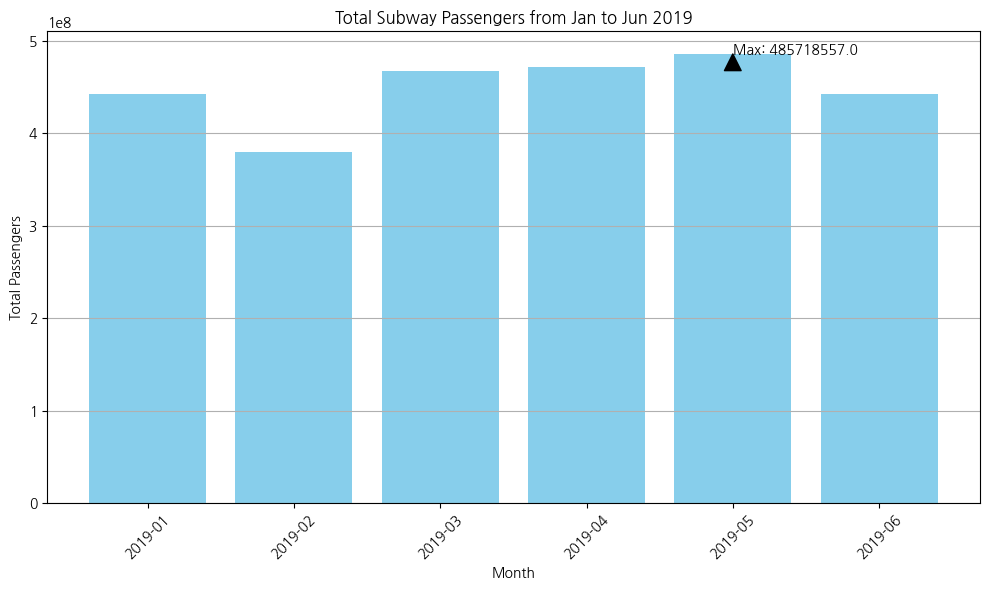

In [211]:
import pandas as pd
import matplotlib.pyplot as plt

# 예시 데이터프레임들: subway201901, subway201902, subway201903, subway201904, subway201905, subway201906
# 데이터프레임 리스트
subway_dfs = [subway201901, subway201902, subway201903, subway201904, subway201905, subway201906]

# 월별 총 승객 수를 저장할 리스트
monthly_passenger_counts = []

# 각 데이터프레임에서 월별 총 승객 수 계산
for df in subway_dfs:
    total_passengers = df['승차총승객수'].sum() + df['하차총승객수'].sum()
    monthly_passenger_counts.append(total_passengers)

# 월 리스트
months = ['2019-01', '2019-02', '2019-03', '2019-04', '2019-05', '2019-06']

# 막대 그래프 그리기
plt.figure(figsize=(10, 6))
plt.bar(months, monthly_passenger_counts, color='skyblue')
plt.title('Total Subway Passengers from Jan to Jun 2019')
plt.xlabel('Month')
plt.ylabel('Total Passengers')
plt.xticks(rotation=45)
plt.grid(axis='y')

# 가장 많이 이용한 달 출력
max_passengers = max(monthly_passenger_counts)
max_month = months[monthly_passenger_counts.index(max_passengers)]
plt.annotate(f'Max: {max_passengers}', xy=(max_month, max_passengers),
             xytext=(max_month, max_passengers + 50000),
             arrowprops=dict(facecolor='black', shrink=0.05))

plt.tight_layout()
plt.show()


## 1월~6월중에 5월에 지하철 승객수가 많다? (기준 :승하자총승객수)


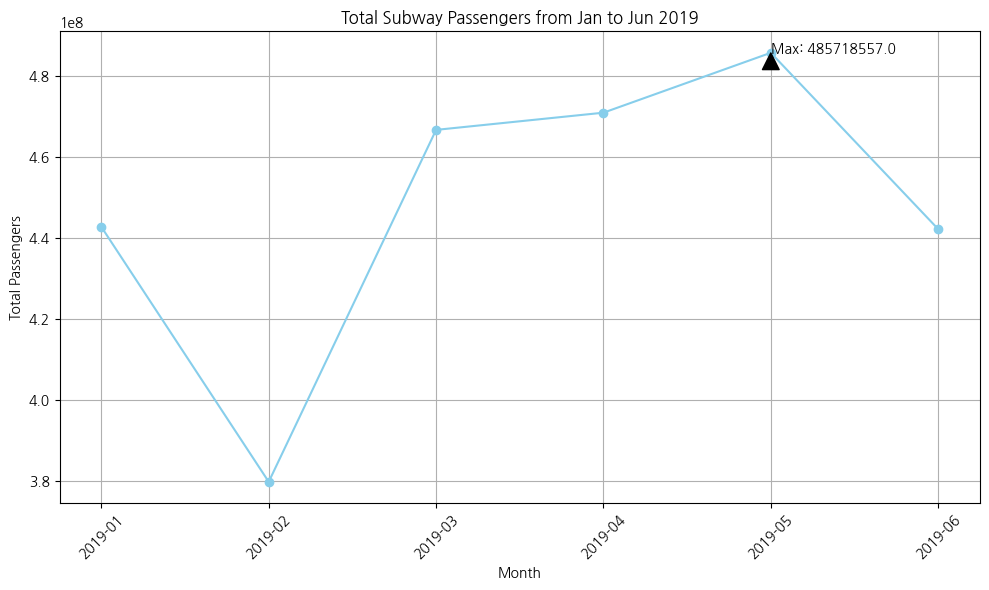

In [212]:
import pandas as pd
import matplotlib.pyplot as plt

# 예시 데이터프레임들: subway201901, subway201902, subway201903, subway201904, subway201905, subway201906
# 데이터프레임 리스트
subway_dfs = [subway201901, subway201902, subway201903, subway201904, subway201905, subway201906]

# 월별 총 승객 수를 저장할 리스트
monthly_passenger_counts = []

# 각 데이터프레임에서 월별 총 승객 수 계산
for df in subway_dfs:
    total_passengers = df['승차총승객수'].sum() + df['하차총승객수'].sum()
    monthly_passenger_counts.append(total_passengers)

# 월 리스트
months = ['2019-01', '2019-02', '2019-03', '2019-04', '2019-05', '2019-06']

# 꺾은 선 그래프 그리기
plt.figure(figsize=(10, 6))
plt.plot(months, monthly_passenger_counts, marker='o', color='skyblue', linestyle='-')
plt.title('Total Subway Passengers from Jan to Jun 2019')
plt.xlabel('Month')
plt.ylabel('Total Passengers')
plt.xticks(rotation=45)
plt.grid()

# 최대 승객 수와 월 표시
max_passengers = max(monthly_passenger_counts)
max_month = months[monthly_passenger_counts.index(max_passengers)]
plt.annotate(f'Max: {max_passengers}', xy=(max_month, max_passengers),
             xytext=(max_month, max_passengers + 50000),
             arrowprops=dict(facecolor='black', shrink=0.05))

plt.tight_layout()
plt.show()


## 요일중에서 목요일에 지하철 승객수가 많다? (기준 :승하자총승객수)


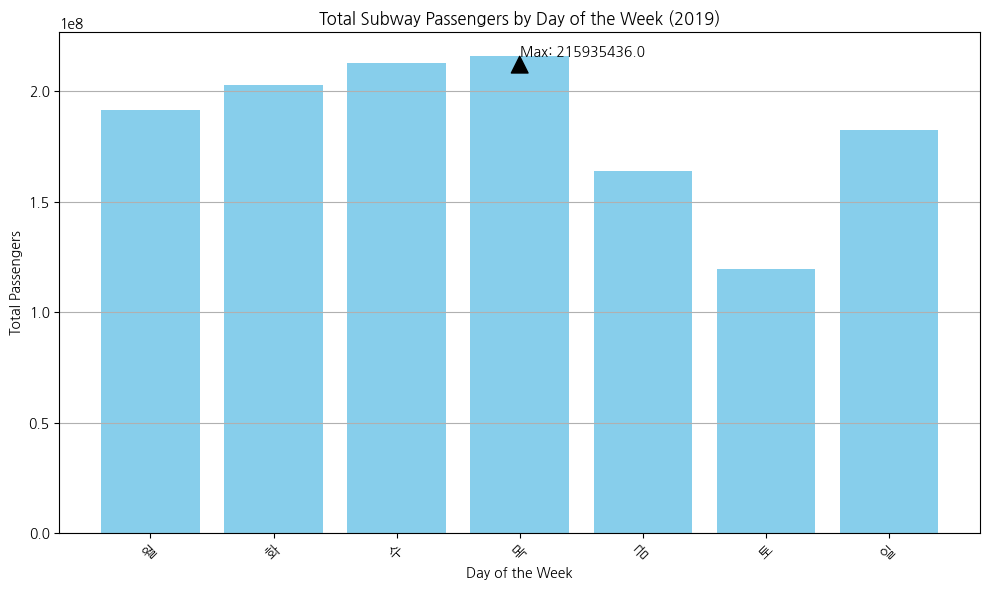

In [213]:
import pandas as pd
import matplotlib.pyplot as plt

# 예시 데이터프레임: subway2019 (가정)
# '요일' 열이 '월', '화', '수', '목', '금', '토', '일' 등의 형식으로 되어 있다고 가정합니다.


# 요일별로 승하자 총 승객 수 합산
weekday_passenger_counts = subway2019.groupby('요일')['승하자총승객수'].sum().reset_index()

# 요일 순서 설정 (주간 기준)
weekday_order = ['월', '화', '수', '목', '금', '토', '일']
weekday_passenger_counts['요일'] = pd.Categorical(weekday_passenger_counts['요일'], categories=weekday_order, ordered=True)

# 정렬
weekday_passenger_counts = weekday_passenger_counts.sort_values('요일')

# 막대 그래프 그리기
plt.figure(figsize=(10, 6))
plt.bar(weekday_passenger_counts['요일'], weekday_passenger_counts['승하자총승객수'], color='skyblue')
plt.title('Total Subway Passengers by Day of the Week (2019)')
plt.xlabel('Day of the Week')
plt.ylabel('Total Passengers')
plt.xticks(rotation=45)
plt.grid(axis='y')

# 목요일에 대한 주석 추가
if '목' in weekday_passenger_counts['요일'].values:
    thursday_passengers = weekday_passenger_counts.loc[weekday_passenger_counts['요일'] == '목', '승하자총승객수'].values[0]
    plt.annotate(f'Max: {thursday_passengers}', xy=('목', thursday_passengers),
                 xytext=('목', thursday_passengers + 50000),
                 arrowprops=dict(facecolor='black', shrink=0.05))
else:
    print("목요일에 대한 데이터가 없습니다.")

plt.tight_layout()
plt.show()


## 일자별(월일별) 승하차승객수 그래프 그려 볼까요? (기준 :승하자총승객수)


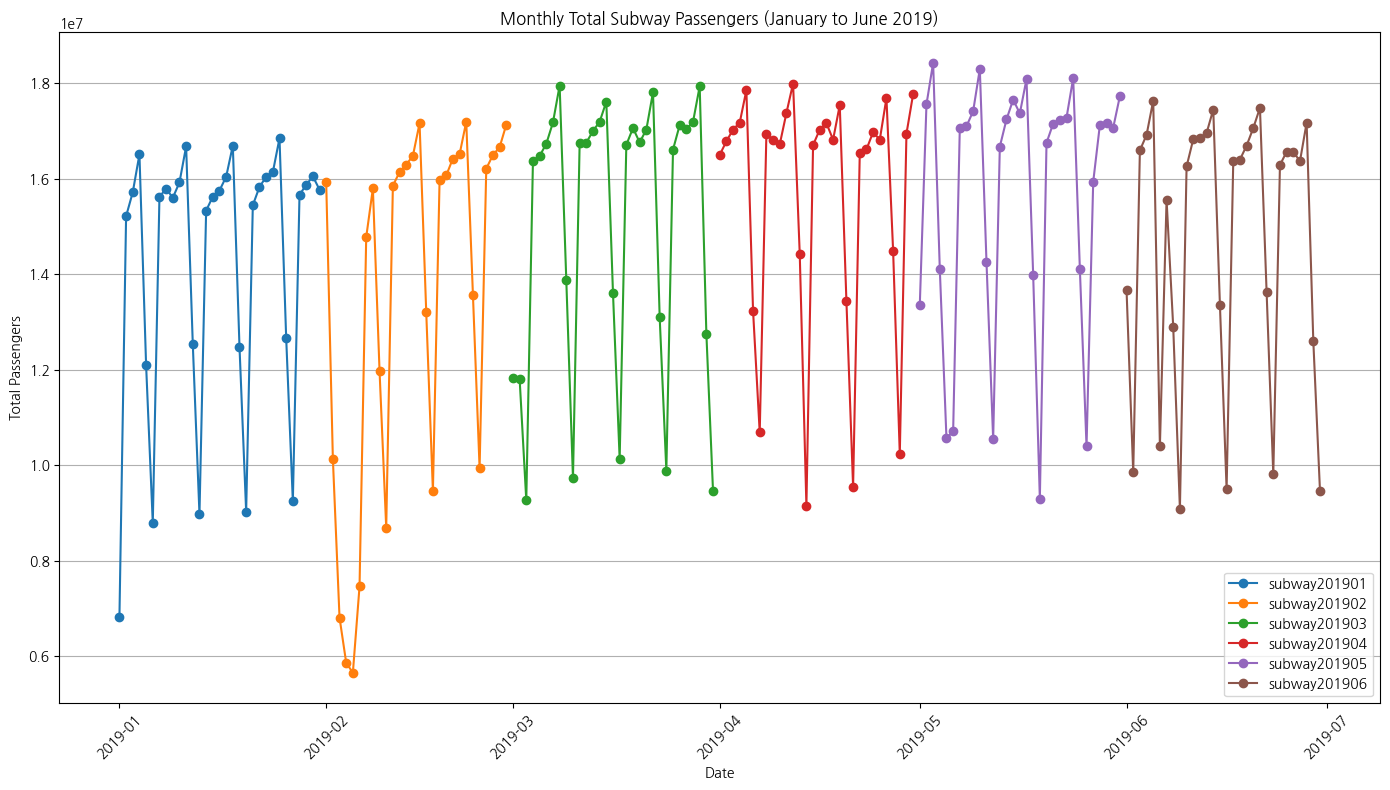

In [214]:
import pandas as pd
import matplotlib.pyplot as plt

# 전처리된 데이터 로드
subway_data = {
    'subway201901': subway201901,
    'subway201902': subway201902,
    'subway201903': subway201903,
    'subway201904': subway201904,
    'subway201905': subway201905,
    'subway201906': subway201906,
}

# 월별 그래프 그리기
plt.figure(figsize=(14, 8))

for month, df in subway_data.items():
    # 승하자 총 승객 수 계산
    df['승하자총승객수'] = df['승차총승객수'] + df['하차총승객수']

    # 사용일자별 승하자 총 승객 수 합산
    monthly_passenger_counts = df.groupby('사용일자')['승하자총승객수'].sum().reset_index()

    # 사용일자 데이터 타입을 datetime으로 변환
    monthly_passenger_counts['사용일자'] = pd.to_datetime(monthly_passenger_counts['사용일자'], format='%Y%m%d')

    # 그래프 그리기
    plt.plot(monthly_passenger_counts['사용일자'], monthly_passenger_counts['승하자총승객수'], marker='o', linestyle='-', label=month)

# 그래프 제목 및 레이블 설정
plt.title('Monthly Total Subway Passengers (January to June 2019)')
plt.xlabel('Date')
plt.ylabel('Total Passengers')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()


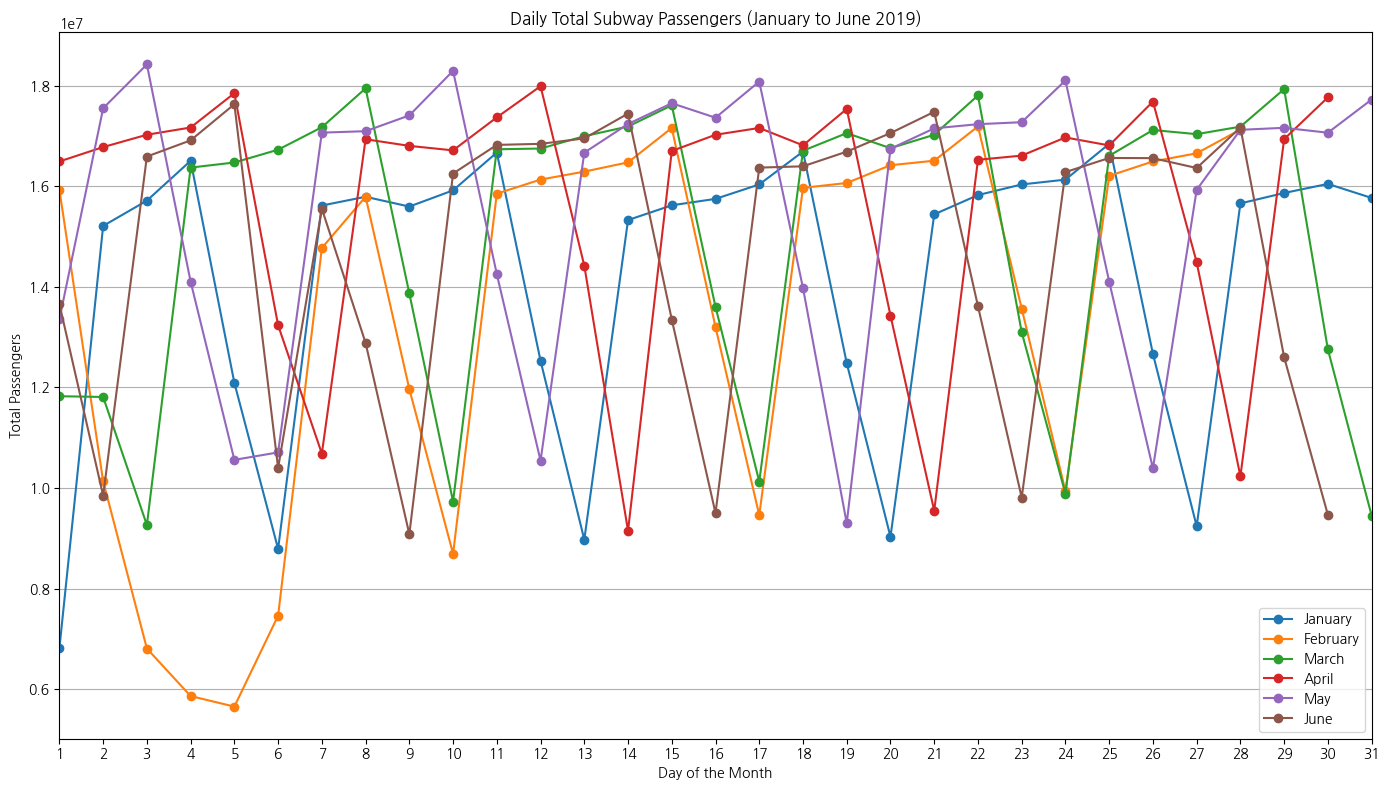

In [215]:
import pandas as pd
import matplotlib.pyplot as plt

# 전처리된 데이터 로드
subway_data = {
    'January': subway201901,
    'February': subway201902,
    'March': subway201903,
    'April': subway201904,
    'May': subway201905,
    'June': subway201906,
}

# 월별 그래프 그리기
plt.figure(figsize=(14, 8))

for month, df in subway_data.items():
    # 승하자 총 승객 수 계산
    df['승하자총승객수'] = df['승차총승객수'] + df['하차총승객수']

    # 사용일자별 승하자 총 승객 수 합산
    daily_passenger_counts = df.groupby('사용일자')['승하자총승객수'].sum().reset_index()

    # 사용일자 데이터 타입을 datetime으로 변환
    daily_passenger_counts['사용일자'] = pd.to_datetime(daily_passenger_counts['사용일자'], format='%Y%m%d')

    # 일(day) 추출하여 새로운 컬럼 추가
    daily_passenger_counts['일'] = daily_passenger_counts['사용일자'].dt.day

    # 그래프 그리기
    plt.plot(daily_passenger_counts['일'], daily_passenger_counts['승하자총승객수'], marker='o', linestyle='-', label=month)

# 그래프 제목 및 레이블 설정
plt.title('Daily Total Subway Passengers (January to June 2019)')
plt.xlabel('Day of the Month')
plt.ylabel('Total Passengers')
plt.xticks(range(1, 32))  # X축을 1일부터 31일까지 설정
plt.xlim(1, 31)  # X축 범위 설정
plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()


## 가장 승객이 많이 타는 승차역은?


In [216]:
import pandas as pd

# 승차역별 승차 총 승객 수 합산
most_passengers_station = subway2019.groupby('역명')['승차총승객수'].sum().reset_index()

# 가장 승객이 많이 타는 승차역 찾기
most_passengers_station = most_passengers_station.sort_values(by='승차총승객수', ascending=False)

# 결과 출력
top_station = most_passengers_station.iloc[0]  # 가장 승객이 많이 타는 역
print(f"가장 승객이 많이 타는 승차역: {top_station['역명']}, 승차 총 승객 수: {top_station['승차총승객수']}")


가장 승객이 많이 타는 승차역: 강남, 승차 총 승객 수: 9162353.0


In [217]:
import pandas as pd

# 승차역별 승차 총 승객 수 합산
most_passengers_station = subway2019.groupby('역명')['승차총승객수'].sum().reset_index()

# 승차 총 승객 수 기준으로 내림차순 정렬
most_passengers_station = most_passengers_station.sort_values(by='승차총승객수', ascending=False)

# 상위 10개 역 출력
top_10_stations = most_passengers_station.head(10)
print("상위 10개 승차역:")
print(top_10_stations)


상위 10개 승차역:
          역명     승차총승객수
11        강남  9162353.0
413       잠실  8989723.0
33     고속터미널  8636280.0
496     홍대입구  8516939.0
247      서울역  8322552.0
214       사당  6420281.0
302       신림  6259755.0
429     종로3가  5651751.0
255       선릉  5641645.0
51   구로디지털단지  5579114.0


## 노선별로 역별/요일별 승차승객수를 비교해 볼수 있을까? (1~9호선, 역별/요일별 heatmap)


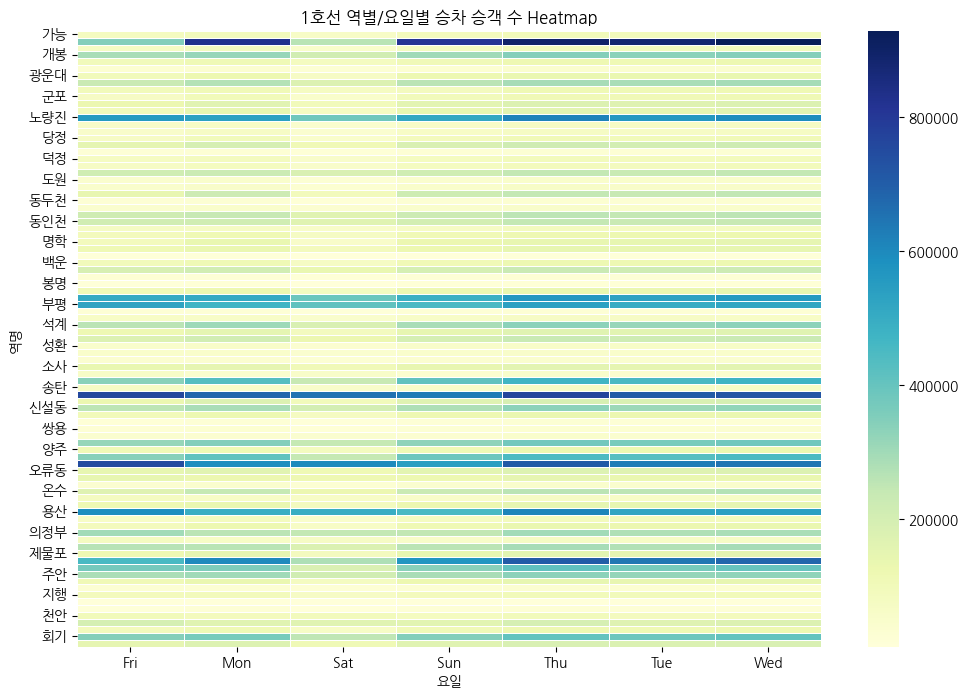

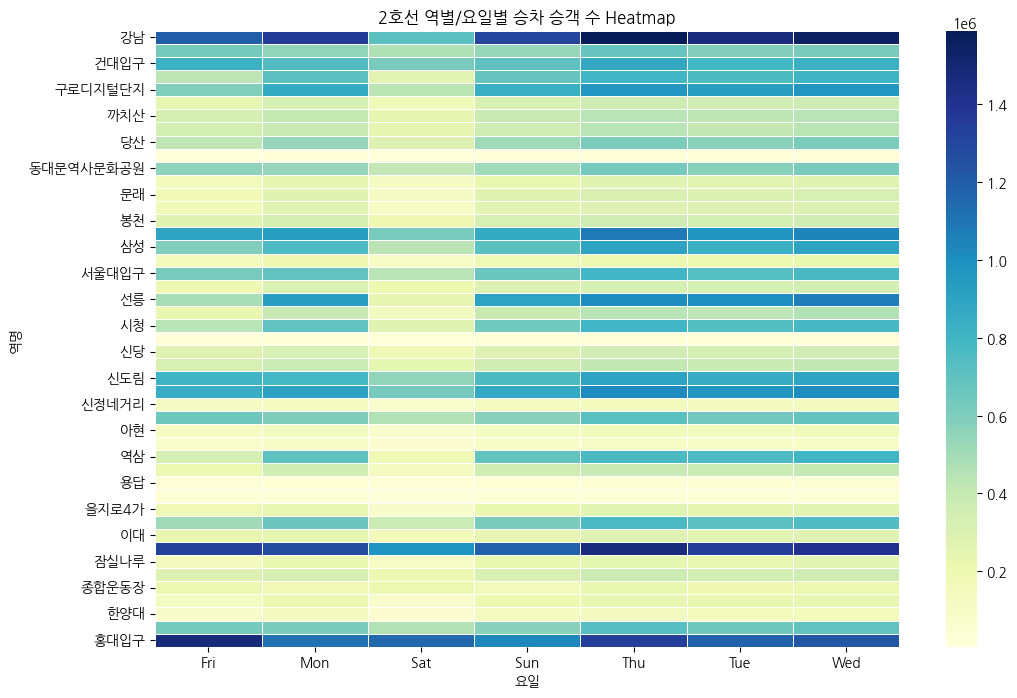

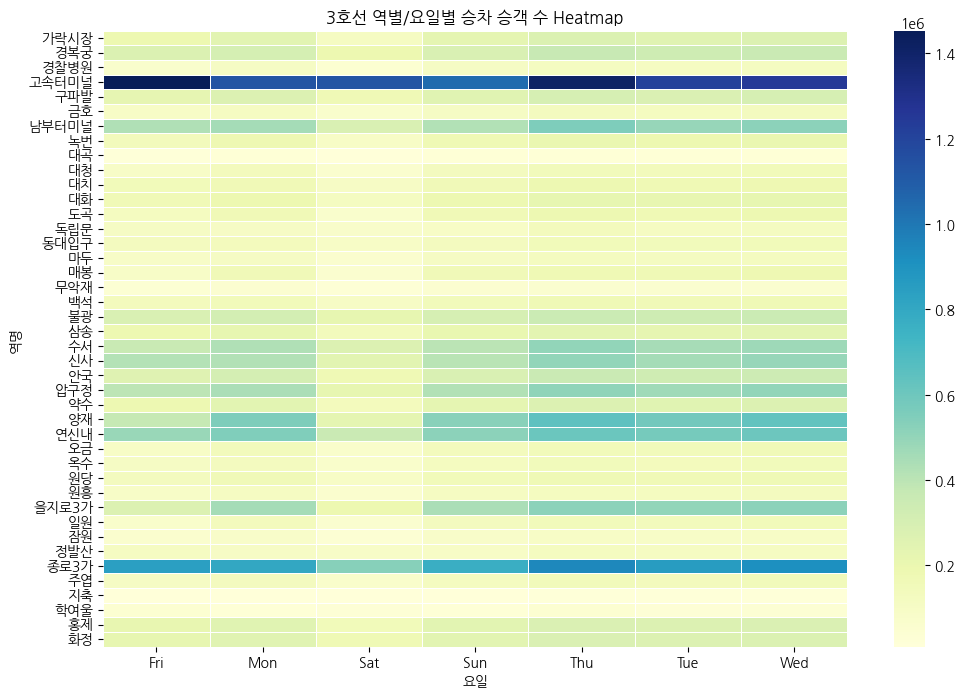

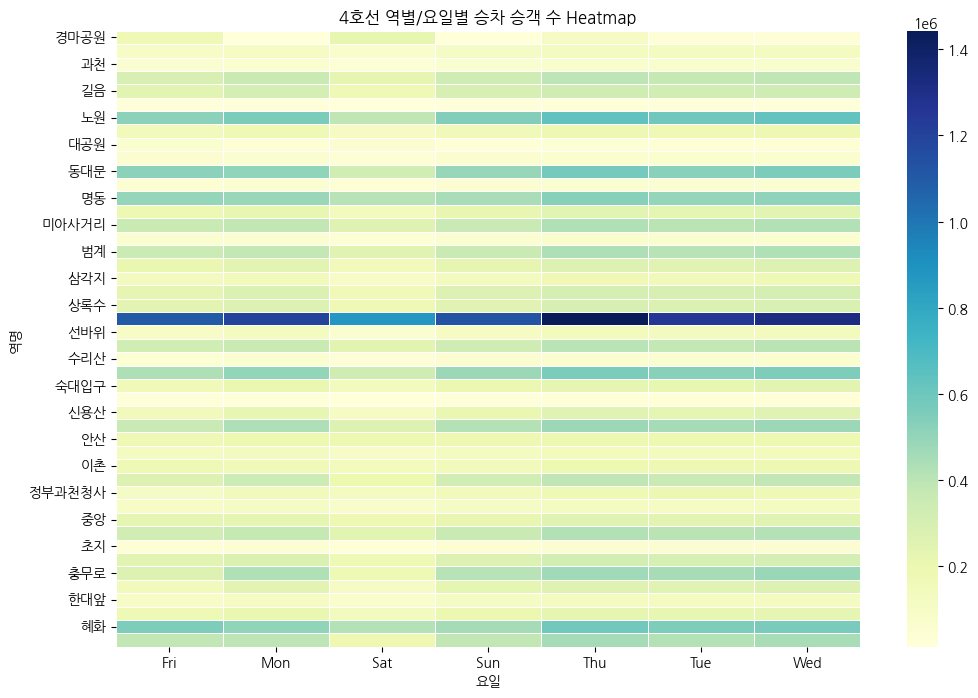

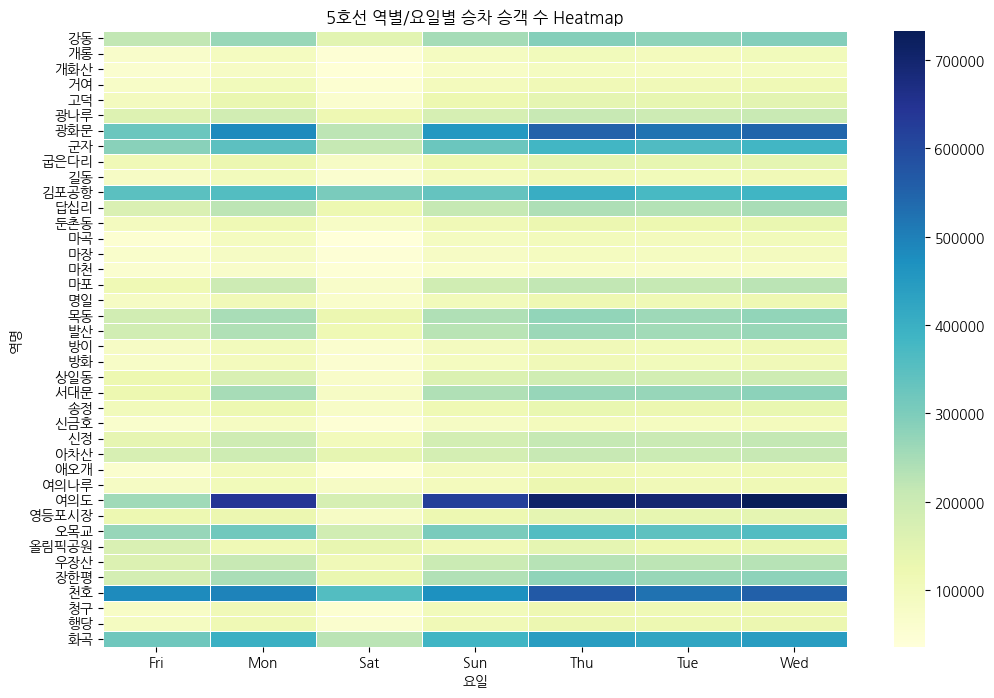

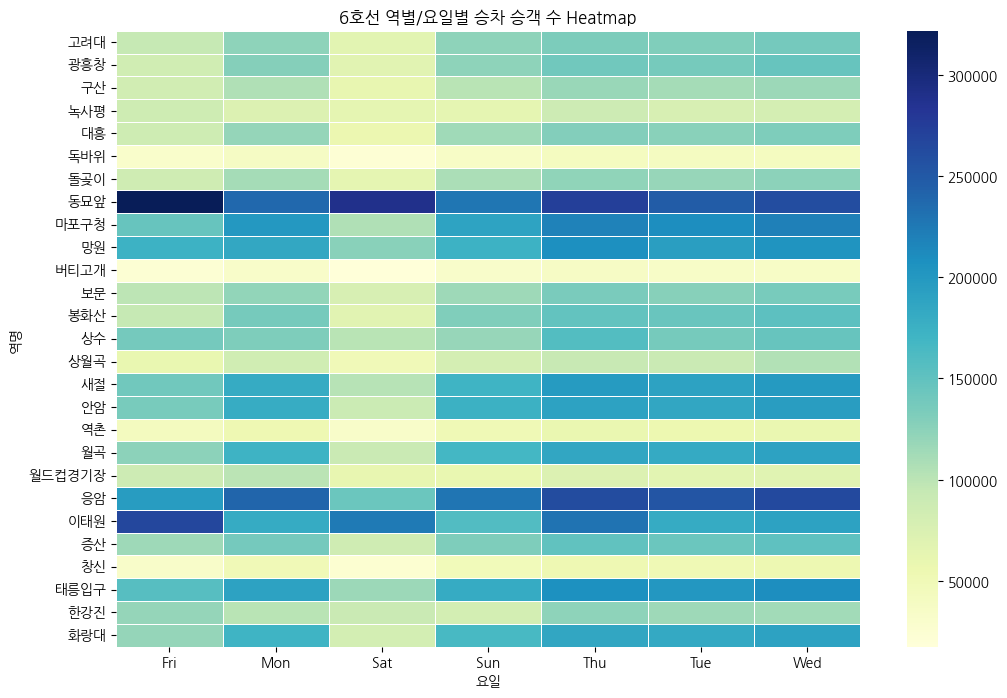

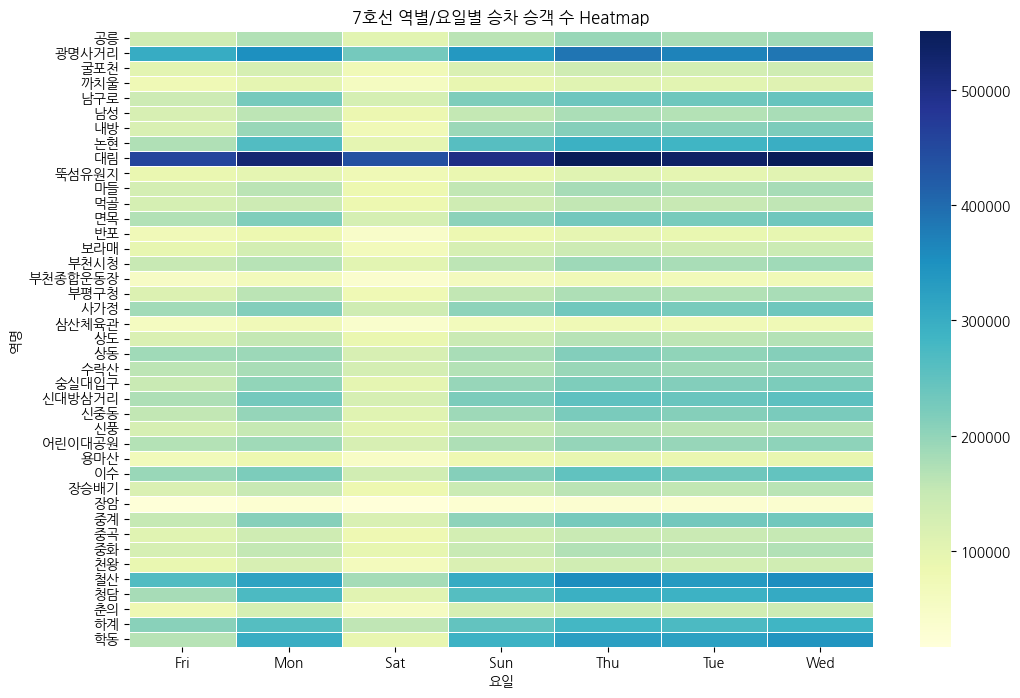

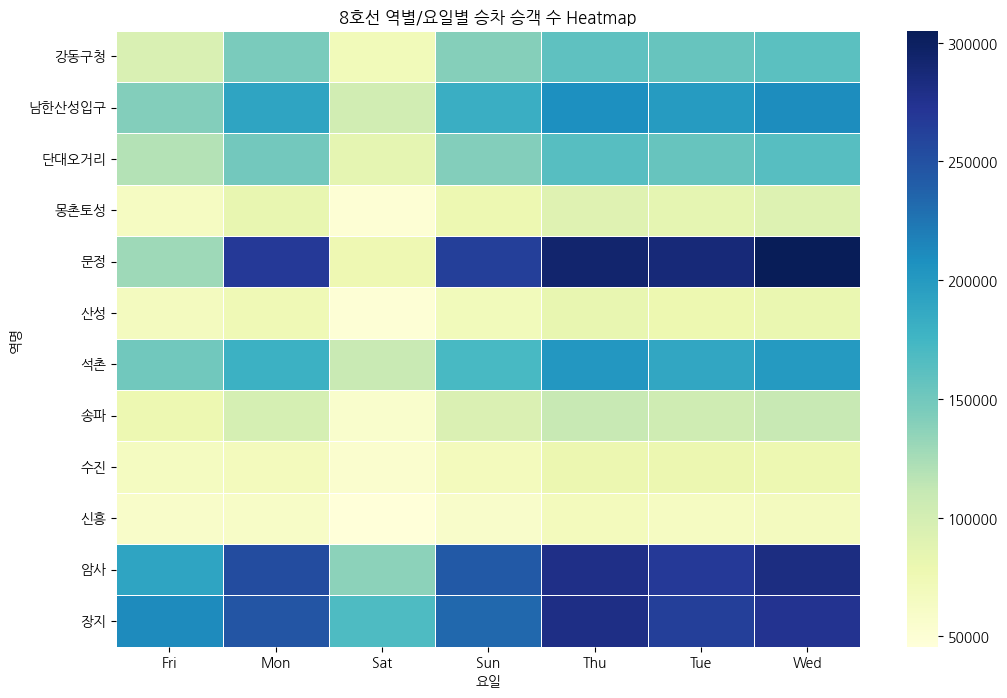

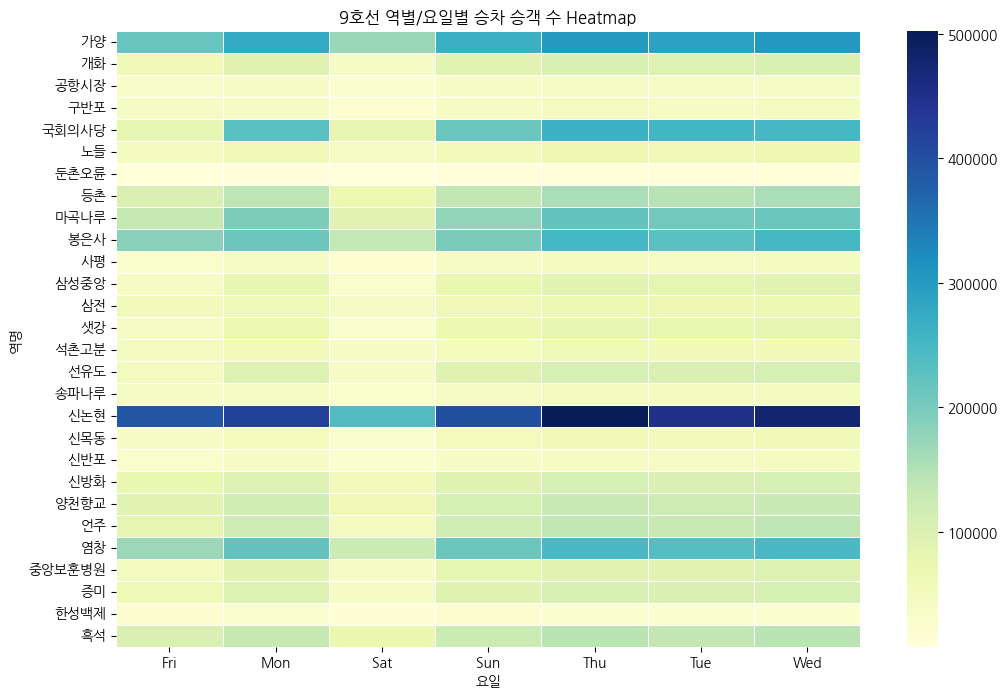

In [218]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# subway2019 데이터가 있다고 가정합니다.
# subway2019 = pd.DataFrame(...)

# 요일을 영어로 변환하는 사전 생성
day_mapping = {'월': 'Mon', '화': 'Tue', '수': 'Wed', '목': 'Thu', '금': 'Fri', '토': 'Sat', '일': 'Sun'}

# 요일을 영어로 변환
subway2019['요일'] = subway2019['요일'].map(day_mapping)

# 노선별로 히트맵을 생성하는 함수
def create_heatmap_for_line(line_name):
    # 노선에 맞는 데이터 필터링
    line_data = subway2019[subway2019['노선명'] == line_name]

    # 역별, 요일별 승차 총 승객 수 집계
    heatmap_data = line_data.groupby(['역명', '요일'])['승차총승객수'].sum().unstack().fillna(0)

    # 히트맵 그리기
    plt.figure(figsize=(12, 8))
    sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False, fmt='.0f', linewidths=.5)
    plt.title(f'{line_name} 역별/요일별 승차 승객 수 Heatmap')
    plt.show()

# 1호선부터 9호선까지 히트맵 생성
for line_num in range(1, 10):
    create_heatmap_for_line(f'{line_num}호선')


## 1호선에서 가장 하자를 많이 하는 역은? (groupby)


In [219]:
import pandas as pd

# 1호선 데이터 필터링
line_1_data = subway2019[subway2019['노선명'] == '1호선']

# 하차역별 하차 총 승객 수 합산
most_passengers_exit_station = line_1_data.groupby('역명')['하차총승객수'].sum().reset_index()

# 하차 총 승객 수 기준으로 내림차순 정렬
most_passengers_exit_station = most_passengers_exit_station.sort_values(by='하차총승객수', ascending=False)

# 가장 하차 승객이 많은 역 출력
top_exit_station = most_passengers_exit_station.head(1)
print("1호선에서 가장 하차 승객이 많은 역:")
print(top_exit_station)


1호선에서 가장 하차 승객이 많은 역:
        역명     하차총승객수
1  가산디지털단지  5162383.0


## 2호선중에서 어느 역에서 승차가 가장 많이 발생할까? (Folium 역 표시)

In [220]:
import pandas as pd
import folium

# 위도와 경도 정보를 담고 있는 CSV 파일 읽기
lat_lon_data = pd.read_csv('/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/지하철노선위경도정보2.csv')

# subway2019 데이터 프레임 생성 (이전에 생성한 데이터를 사용)
# subway2019 = pd.DataFrame(...)

# 2호선 데이터 필터링
line_2_data = subway2019[subway2019['노선명'] == '2호선']

# 승차역별 승차 총 승객 수 합산
most_passengers_entry_station = line_2_data.groupby('역명')['승차총승객수'].sum().reset_index()

# 승차 총 승객 수 기준으로 내림차순 정렬
most_passengers_entry_station = most_passengers_entry_station.sort_values(by='승차총승객수', ascending=False)

# 가장 승차 승객이 많은 역
top_entry_station = most_passengers_entry_station.head(1)

# 출력
print("2호선에서 가장 승차 승객이 많은 역:")
print(top_entry_station)

# 가장 승차 승객이 많은 역의 이름
top_station_name = top_entry_station['역명'].values[0]

# 위도와 경도 정보 가져오기
top_station_info = lat_lon_data[lat_lon_data['역이름'] == top_station_name]

# Folium 지도 생성 (위도, 경도에 따라 중심 설정)
m = folium.Map(location=[top_station_info['위도'].values[0], top_station_info['경도'].values[0]], zoom_start=14)

# 가장 승차가 많이 발생한 역 표시
folium.Marker(
    location=[top_station_info['위도'].values[0], top_station_info['경도'].values[0]],
    popup=f"{top_station_name}\n승차 승객 수: {top_entry_station['승차총승객수'].values[0]}",
    icon=folium.Icon(color='blue')
).add_to(m)

# 지도 표시
m


2호선에서 가장 승차 승객이 많은 역:
   역명     승차총승객수
0  강남  9162353.0


In [221]:
import pandas as pd
import folium

# 위도와 경도 정보를 담고 있는 CSV 파일 읽기
lat_lon_data = pd.read_csv('/content/drive/MyDrive/003.지하철 이용승객 EDA분석_숙제_20220914/실습/지하철노선위경도정보2.csv')

# subway2019 데이터 프레임 생성 (이전에 생성한 데이터를 사용)
# subway2019 = pd.DataFrame(...)

# 모든 역에 대해 승차총승객수와 하차총승객수 합산
total_passengers = subway2019.groupby('역명').agg({
    '승차총승객수': 'sum',
    '하차총승객수': 'sum'
}).reset_index()

# 총승하차승객수 계산
total_passengers['총승하차승객수'] = total_passengers['승차총승객수'] + total_passengers['하차총승객수']

# 총승하차승객수가 많은 상위 10개 역 추출
top_stations = total_passengers.sort_values(by='총승하차승객수', ascending=False).head(10)

# Folium 지도 생성
m = folium.Map(location=[top_station_info['위도'].values[0], top_station_info['경도'].values[0]], zoom_start=14)

# 상위 10개 역 표시
for index, row in top_stations.iterrows():
    # 해당 역의 위도와 경도 정보 가져오기
    station_info = lat_lon_data[lat_lon_data['역이름'] == row['역명']]

    if not station_info.empty:  # 위도와 경도 정보가 있는 경우
        folium.Marker(
            location=[station_info['위도'].values[0], station_info['경도'].values[0]],
            popup=f"{row['역명']}\n총 승하차 승객 수: {row['총승하차승객수']}",
            icon=folium.Icon(color='blue')
        ).add_to(m)

# 지도 표시
m


In [222]:
top_stations

,역명,승차총승객수,하차총승객수,총승하차승객수
11,강남,9162353.0,9302042.0,18464395.0
413,잠실,8989723.0,8860643.0,17850366.0
496,홍대입구,8516939.0,9040334.0,17557273.0
33,고속터미널,8636280.0,8729616.0,17365896.0
247,서울역,8322552.0,8274574.0,16597126.0
214,사당,6420281.0,6495524.0,12915805.0
302,신림,6259755.0,6134300.0,12394055.0
429,종로3가,5651751.0,5734972.0,11386723.0
255,선릉,5641645.0,5727652.0,11369297.0
24,건대입구,5392722.0,5858288.0,11251010.0


# 비지니스 인사이트
1. 비상 상황 대응

https://www.sedaily.com/NewsView/29UR9CJ0CN
사당역(2호선)으로 64명이 다쳤고, 동대문역사문화공원역(4호선) 49명, 신도림역(2호선) 39명, 당산역(9호선) 39명, 구로디지털단지역(2호선) 33명, 충무로역(3호선)·사당역(4호선) 31명 순
'출입문 끼임'이 747명(30.1%)으로 가장 많았다. 역 구내 사고 604명(24.3%), 열차 내 사고 564명(22.7%), 승강장 발 빠짐 사고 320명(12.9%), 승강기 설비 사고 213명(8.6%)
서울교통공사가 지하철 안전사고로 부상자에게 지급한 치료비는 이 기간 20억 419만원

-->승하차가 많은 역들은 입구를 정비할 필요가 있다고 생각함

2. 관광지 및 문화 콘텐츠 활성화

종로3가 뭔가 관광지로 꾸미고 싶음